# Tracking Validation: NPC1 & NPC4

Cross-session validation of the graph-tracking output (`traversal_df.csv`,
`summary_df.pkl`) against the BPOD record (`reward_df_annotated.csv`), for every
session of NPC1 and NPC4 under `resources/outputs/`.

BPOD's port pokes are sensor events, so they make an independent reference for
the video tracking. Every check below measures how well the two agree.

**Sections**
1. Setup: paths, port layouts, the maze graph
2. Per-session processing: one pass per session that builds every table below
3. **Port-to-port times**: distributions per session, then a summary per subject
4. **Validations**
   - 4.1 Coverage: BPOD trials that have video and tracking
   - 4.2 Reward-on-port: is the animal at the paying port when BPOD logs the poke?
   - 4.3 Residual clock offset and drift between video and BPOD
   - 4.4 Poke latency: tracked arrival at the port → BPOD poke
   - 4.5 Tracked travel time vs BPOD inter-poke interval (travel can't exceed it)
   - 4.6 Physical plausibility: seconds per hop, paths shorter than the shortest path
   - 4.7 Port sequence agreement: tracking-only port sequence vs the BPOD sequence
   - 4.8 Graph legality: illegal transitions, inferred steps, flicker
   - 4.9 Raw DLC quality: likelihood and teleport jumps
5. **Path length vs travel time**: do longer tracked paths take proportionally longer?
6. **Are indirect paths real?** Graph, pixel and second-body-part evidence for every
   indirect trial, a trajectory gallery, and a blind video-review sheet
7. **NPC4 vs NPC1**: is one subject's graph tracking more reliable?
8. QC scorecard: one row per session with pass/warn/fail flags, saved to CSV

**Definitions**
- *Port zone*: a port's leaf node (e.g. `R522`). The reward-on-port check also
  accepts the leaf's parent (e.g. `R411`), matching `session_pipeline.ipynb`,
  because the headstage often sits on the parent while the nose is in the port.
- *Leaf run*: consecutive visits to the same port leaf with no other port leaf in
  between. Flicker of the form leaf→parent→leaf collapses into one run.
- *Tracked travel time* for BPOD trial *t* (poke at A on trial *t−1*, then at B on
  trial *t*): from the end of the A run to the start of the B run that matches
  B's poke.
- *BPOD inter-poke interval (IPI)*: `reward_abs_time[t] − reward_abs_time[t−1]`.
  It includes the time spent at port A, so it is always ≥ the travel time.

In [1]:
import ast
import difflib
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
})

OUTPUTS   = Path('/var/home/almogmeir/Documents/GitHub/NaviGraph/examples/dual_root_tree/resources/outputs')
GRAPH_PKL = Path('/var/home/almogmeir/Documents/GitHub/NaviGraph/FullMazeGrid.pkl')
QC_DIR    = OUTPUTS / 'tracking_validation'
QC_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = ['NPC1', 'NPC4']
FPS = 40

# ── Thresholds (tune here) ───────────────────────────────────────────────────
POKE_WINDOW_S     = 1.0    # tracked port arrival may follow the poke by up to this much
MIN_ON_PORT_PCT   = 60.0   # same acceptance level session_pipeline uses for alignment
WARN_ON_PORT_PCT  = 85.0
MAX_RESID_SHIFT_S = 0.5    # residual video/BPOD offset tolerated before a warning
LOW_LIKELIHOOD    = 0.9
TELEPORT_PX       = 60     # headstage jump between consecutive confident frames
MIN_SEC_PER_HOP   = 0.08   # faster than this per graph hop is not physically plausible
SHIFT_SCAN_S      = 5.0    # ± range of the residual-offset scan
# Which nodes count as "at port p" for travel timing: 'leaf+parent' (default) or
# 'leaf'. The headstage often sits on the parent while the nose is in the port,
# especially for NPC4, so leaf-only misses many arrivals.
PORT_ZONE         = 'leaf+parent'
MIN_DETOUR_FRAMES = 4      # observed (non-inferred) off-path frames needed to call a detour graph-supported
PX_SMOOTH_FRAMES  = 5      # rolling-median window for pixel off-path distance (rejects 1-2 frame glitches)

# Colors: categorical slots in fixed order; status colors are reserved for flags.
SUBJECT_COLOR = {'NPC1': '#2a78d6', 'NPC4': '#eb6834'}
TRACK_COLOR, BPOD_COLOR = '#1baf7a', '#4a3aa7'
STATUS_COLOR = {'pass': '#0ca30c', 'warn': '#fab219', 'fail': '#d03b3b'}
INK, INK2 = '#0b0b0b', '#52514e'

## 1. Port layouts and maze graph

`PORT_LAYOUTS` is copied from the *Port layout configuration* cell of
`session_pipeline.ipynb`. If the wiring changes there, update it here as well.

In [2]:
# (valid_from, valid_until, {port: (leaf, [parent])}); dates DD/MM/YYYY, inclusive.
PORT_LAYOUTS = {
    'NPC1': [
        (None, '01/09/2025', {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L56', ['L43']),
                              4: ('L510', ['L45']), 5: ('L521', ['L410']), 6: ('L525', ['L412']),
                              7: ('R55', ['R42']), 8: ('R59', ['R44'])}),
        ('02/09/2025', '06/09/2025', {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L56', ['L43']),
                                      4: ('L510', ['L45']), 5: ('L521', ['L410']), 6: ('L518', ['L49']),
                                      7: ('R55', ['R42']), 8: ('R59', ['R44'])}),
        ('07/09/2025', '08/09/2025', {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L56', ['L43']),
                                      4: ('L510', ['L45']), 5: ('L521', ['L410']), 6: ('L518', ['L49']),
                                      7: ('R59', ['R44']), 8: ('R55', ['R42'])}),
        ('09/09/2025', None, {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L56', ['L43']),
                              4: ('L510', ['L45']), 5: ('L521', ['L410']), 6: ('L525', ['L412']),
                              7: ('R59', ['R44']), 8: ('R55', ['R42'])}),
    ],
    'NPC4': [
        ('01/03/2026', '16/06/2026', {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L510', ['L45']),
                                      4: ('L56', ['L43']), 5: ('L521', ['L410']), 6: ('L525', ['L412']),
                                      7: ('R59', ['R44']), 8: ('R55', ['R42'])}),
        ('17/06/2026', '18/06/2026', {1: ('R521', ['R410']), 2: ('R526', ['R413']), 3: ('L510', ['L45']),
                                      4: ('L56', ['L43']), 5: ('L530', ['L415']), 6: ('L517', ['L48']),
                                      7: ('R59', ['R44']), 8: ('R55', ['R42'])}),
        ('19/06/2026', None, {1: ('R522', ['R411']), 2: ('R526', ['R413']), 3: ('L510', ['L45']),
                              4: ('L56', ['L43']), 5: ('L521', ['L410']), 6: ('L525', ['L412']),
                              7: ('R59', ['R44']), 8: ('R55', ['R42'])}),
    ],
}


def _date_key(d):
    return None if d is None else (d[6:10], d[3:5], d[0:2])


def resolve_port_layout(subject, session_ddmmyyyy):
    s = _date_key(session_ddmmyyyy)
    for lo, hi, layout in PORT_LAYOUTS[subject]:
        lo, hi = _date_key(lo), _date_key(hi)
        if (lo is None or lo <= s) and (hi is None or s <= hi):
            return layout
    raise KeyError(f'No port layout covers {subject} {session_ddmmyyyy}')


def session_dirs(subject):
    """Session folders named DD_MM_YYYY, in chronological order."""
    dirs = [p for p in (OUTPUTS / subject).iterdir()
            if p.is_dir() and p.name[:2].isdigit() and (p / 'traversal_df.csv').exists()]
    return sorted(dirs, key=lambda p: (p.name[6:10], p.name[3:5], p.name[0:2]))


for subj in SUBJECTS:
    print(subj, [p.name for p in session_dirs(subj)])

NPC1 ['07_08_2025', '12_08_2025', '13_08_2025', '14_08_2025', '18_08_2025', '19_08_2025', '20_08_2025', '21_08_2025', '24_08_2025', '27_08_2025', '01_09_2025', '02_09_2025', '03_09_2025', '04_09_2025', '07_09_2025', '08_09_2025', '09_09_2025', '10_09_2025', '11_09_2025']
NPC4 ['03_04_2026', '05_04_2026', '07_04_2026', '09_04_2026', '13_04_2026', '14_04_2026', '15_04_2026', '10_05_2026', '12_05_2026', '13_05_2026', '14_05_2026', '17_05_2026', '18_05_2026', '19_05_2026', '20_05_2026', '24_05_2026', '25_05_2026', '26_05_2026', '01_06_2026', '02_06_2026', '07_06_2026', '08_06_2026', '09_06_2026', '16_06_2026', '17_06_2026', '18_06_2026', '22_06_2026', '24_06_2026']


In [3]:
with open(GRAPH_PKL, 'rb') as f:
    _maze = pickle.load(f)

G = nx.Graph()
for _key in _maze['mappings']['edges']:
    _a, _b = _key.split('_')
    G.add_edge(_a, _b)


# Augmented graph: corridors become tuple-states, virtual leaf↔parent links stay
# direct node↔node. Same construction as ImprovedMazeTraversalFixer /
# traversal_quality_analysis.ipynb, so "legal" means the same thing everywhere.
def _is_virtual_edge(u, v):
    lvl = lambda s: s[1] if len(s) >= 2 and s[0] in ('L', 'R') else None
    lu, lv = lvl(u), lvl(v)
    return bool(lu and lv and {lu, lv} == {'4', '5'})


G_aug = nx.Graph()
G_aug.add_nodes_from(G.nodes())
for u, v in G.edges():
    if G.degree(u) == 1 or G.degree(v) == 1 or _is_virtual_edge(u, v):
        G_aug.add_edge(u, v)
    else:
        e = tuple(sorted((u, v)))
        G_aug.add_edge(u, e)
        G_aug.add_edge(v, e)

print(f'G: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (tree: {nx.is_tree(G)})')
print(f'G_aug: {G_aug.number_of_nodes()} states')

G: 126 nodes, 125 edges (tree: True)
G_aug: 187 states


## 2. Per-session processing

`process_session` reads one session folder and returns:

- `trials`: one row per BPOD trial. Port from/to, BPOD IPI, tracked travel
  time, poke latency, tracked vs shortest hops, inferred and illegal steps on the
  way, plus a `status` explaining why a trial has no travel time.
- `runs`: the tracking-only sequence of port leaf runs (it never looks at BPOD).
- `qc`: one row of session-level metrics.

Frames are video frames (`frame_idx_global`), and time is `frame / FPS`.

In [4]:
def _flatten_cols(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [a if b == '' else f'{a}_{b}' for a, b in df.columns]
    return df


def _state(lt, node, edge):
    """traversal_df row → G_aug state (node name or sorted edge tuple)."""
    if lt == 'node':
        return node if isinstance(node, str) else None
    if isinstance(edge, str) and edge.startswith('('):
        try:
            return tuple(sorted(ast.literal_eval(edge)))
        except Exception:
            return None
    return None


class LocationLookup:
    """Where was the animal at frame f?  Interval lookup over traversal_df rows."""

    def __init__(self, trav):
        t = trav.sort_values('start_frame_global')
        self.start = t['start_frame_global'].to_numpy()
        self.end = t['end_frame_global'].to_numpy()
        self.node = t['headstage_graph_node'].where(t['location_type'] == 'node').to_numpy(dtype=object)

    def node_at(self, frames):
        frames = np.asarray(frames)
        i = np.searchsorted(self.start, frames, side='right') - 1
        ok = (i >= 0) & (frames <= self.end[np.clip(i, 0, None)])
        out = np.full(len(frames), None, dtype=object)
        out[ok] = self.node[i[ok]]
        return out


def port_runs(trav, node_to_port):
    """Collapse port-zone visits into runs (no other port's zone in between)."""
    nodes = trav[(trav['location_type'] == 'node')
                 & trav['headstage_graph_node'].isin(node_to_port)].sort_values('start_frame_global')
    runs = []
    for node, s, e in zip(nodes['headstage_graph_node'], nodes['start_frame_global'], nodes['end_frame_global']):
        p = node_to_port[node]
        if runs and runs[-1]['port'] == p:
            runs[-1].update(end=e, last_node=node)
        else:
            runs.append({'port': p, 'start': s, 'end': e, 'first_node': node, 'last_node': node})
    return pd.DataFrame(runs, columns=['port', 'start', 'end', 'first_node', 'last_node'])


def path_between(node_rows, f0, f1):
    """Collapsed node sequence strictly between frames f0 and f1."""
    seg = node_rows[(node_rows['start_frame_global'] > f0) & (node_rows['start_frame_global'] < f1)]
    seq = seg['headstage_graph_node'].tolist()
    return [n for i, n in enumerate(seq) if i == 0 or n != seq[i - 1]]


def _edge_key(e):
    if isinstance(e, str) and e.startswith('('):
        try:
            return frozenset(ast.literal_eval(e))
        except Exception:
            return None
    return None


def region_centroids(summ):
    """Pixel centroid of every node and corridor, from confident raw frames."""
    ok = summ['headstage_likelihood'] >= LOW_LIKELIHOOD
    c_node = summ[ok].groupby('headstage_graph_node')[['headstage_x', 'headstage_y']].median()
    nodes = {n: v for n, v in zip(c_node.index, c_node.to_numpy())}
    e = summ.loc[ok, ['headstage_graph_edge', 'headstage_x', 'headstage_y']].dropna()
    e = e.assign(key=e['headstage_graph_edge'].map(_edge_key)).dropna(subset=['key'])
    c_edge = e.groupby('key')[['headstage_x', 'headstage_y']].median()
    edges = {k: v for k, v in zip(c_edge.index, c_edge.to_numpy())}
    hop = np.median([np.hypot(*(nodes[a] - nodes[b])) for a, b in G.edges() if a in nodes and b in nodes])
    return nodes, edges, hop


def path_polyline(path, nodes, edges):
    """Pixel polyline node → corridor → node … along a graph path."""
    pts = []
    for i, n in enumerate(path):
        if i and frozenset((path[i - 1], n)) in edges:
            pts.append(edges[frozenset((path[i - 1], n))])
        if n in nodes:
            pts.append(nodes[n])
    return np.array(pts) if pts else None


def dist_to_polyline(px, py, poly):
    if len(poly) == 1:
        return np.hypot(px - poly[0, 0], py - poly[0, 1])
    a, ab = poly[:-1], np.diff(poly, axis=0)
    apx, apy = px[:, None] - a[None, :, 0], py[:, None] - a[None, :, 1]
    L2 = np.maximum((ab ** 2).sum(1), 1e-9)
    t = np.clip((apx * ab[:, 0] + apy * ab[:, 1]) / L2, 0, 1)
    return np.hypot(apx - t * ab[:, 0], apy - t * ab[:, 1]).min(1)


def offpath_px(x, y, lk, poly):
    """Largest sustained pixel distance from the shortest-path corridor."""
    ok = lk >= LOW_LIKELIHOOD
    if poly is None or ok.sum() < 3:
        return np.nan
    d = dist_to_polyline(x[ok], y[ok], poly)
    return pd.Series(d).rolling(PX_SMOOTH_FRAMES, center=True, min_periods=3).median().max()


def px_path_length(x, y, lk):
    ok = lk >= LOW_LIKELIHOOD
    return np.minimum(np.hypot(np.diff(x[ok]), np.diff(y[ok])), TELEPORT_PX).sum() if ok.sum() > 1 else np.nan

In [5]:
def process_session(subject, sdir):
    date = sdir.name
    layout = resolve_port_layout(subject, date.replace('_', '/'))
    leaf_to_port = {leaf: p for p, (leaf, _) in layout.items()}
    zone = {p: {leaf, *parents} for p, (leaf, parents) in layout.items()}
    node_to_port = dict(leaf_to_port)
    if PORT_ZONE == 'leaf+parent':
        node_to_port.update({par: p for p, (_, parents) in layout.items() for par in parents})

    trav = pd.read_csv(sdir / 'traversal_df.csv').sort_values('start_frame_global').reset_index(drop=True)
    reward = pd.read_csv(sdir / 'reward_df_annotated.csv').sort_values('trial_idx').reset_index(drop=True)
    if 'reward_abs_time' not in reward.columns:   # sessions processed before the column rename
        reward = reward.rename(columns={'abs_time': 'reward_abs_time'})
    summ = _flatten_cols(pd.read_pickle(sdir / 'summary_df.pkl'))
    lookup = LocationLookup(trav)
    node_rows = trav[trav['location_type'] == 'node']
    summ = summ.sort_values('frame_idx_global').reset_index(drop=True)
    cen_nodes, cen_edges, hop_px = region_centroids(summ)
    S_fr = summ['frame_idx_global'].to_numpy()
    S = {bp: (summ[f'{bp}_x'].to_numpy(), summ[f'{bp}_y'].to_numpy(), summ[f'{bp}_likelihood'].to_numpy())
         for bp in ('headstage', 'midbody')}
    trav_edge_key = trav['headstage_graph_edge'].map(_edge_key)

    # ── BPOD poke frames (the pipeline marks one reward_node frame per trial) ──
    rframe = summ.loc[summ['reward_node'] == True].groupby('trial_idx')['frame_idx_global'].first()
    reward['poke_frame'] = reward['trial_idx'].map(rframe)

    # ── Graph legality over the whole traversal ──
    states = [_state(lt, n, e) for lt, n, e in
              zip(trav['location_type'], trav['headstage_graph_node'], trav['headstage_graph_edge'])]
    tri = trav['trial_idx'].to_numpy()
    illegal = np.zeros(len(trav), dtype=bool)   # True on the row a bad transition lands on
    n_checked = 0
    for i in range(1, len(trav)):
        a, b = states[i - 1], states[i]
        if tri[i] != tri[i - 1] or a is None or b is None:
            continue
        n_checked += 1
        if a != b and not (a in G_aug and b in G_aug and G_aug.has_edge(a, b)):
            illegal[i] = True
    trav['illegal'] = illegal

    # ── Tracking-only port sequence ──
    runs = port_runs(trav, node_to_port)
    leaf_only_runs = port_runs(trav, leaf_to_port)
    runs['subject'], runs['session'] = subject, date

    # ── BPOD-anchored trial table ──
    run_start = runs['start'].to_numpy()
    w = int(POKE_WINDOW_S * FPS)
    rows = []
    for k in range(len(reward)):
        r = reward.iloc[k]
        prev = reward.iloc[k - 1] if k > 0 else None
        row = {'subject': subject, 'session': date, 'trial_idx': int(r['trial_idx']),
               'port_from': np.nan if prev is None else int(prev['reward_port']),
               'port_to': int(r['reward_port']), 'poke_frame': r['poke_frame'],
               'poke_time_s': r['reward_abs_time'],
               'bpod_ipi_s': np.nan if prev is None else r['reward_abs_time'] - prev['reward_abs_time'],
               'rewarded': r.get('reward_size', 0) > 0}
        F = r['poke_frame']
        if prev is None:
            row['status'] = 'first_trial'
        elif pd.isna(F) or pd.isna(prev['poke_frame']):
            row['status'] = 'not_in_video'
        elif row['port_from'] == row['port_to']:
            row['status'] = 'same_port'
        else:
            A, B, Fp = row['port_from'], row['port_to'], prev['poke_frame']
            row['sp_hops'] = nx.shortest_path_length(G, layout[A][0], layout[B][0])
            # B run matching this poke: last B run starting before F + window, after A's poke
            cand = np.where((runs['port'].to_numpy() == B) & (run_start <= F + w) & (run_start > Fp - w))[0]
            if len(cand) == 0:
                row['status'] = 'no_arrival_tracked'
            elif cand[-1] == 0 or runs.iloc[cand[-1] - 1]['port'] != A:
                j = cand[-1]
                row['status'] = 'prev_run_not_from_port'
                row['tracked_prev_port'] = np.nan if j == 0 else runs.iloc[j - 1]['port']
            else:
                j = cand[-1]
                dep, arr = runs.iloc[j - 1]['end'], runs.iloc[j]['start']
                path = path_between(node_rows, dep, arr)
                dep_node, arr_node = runs.iloc[j - 1]['last_node'], runs.iloc[j]['first_node']
                sp = nx.shortest_path(G, dep_node, arr_node)
                end_hops = len(sp) - 1
                sp_set = set(sp)
                in_win = (trav['start_frame_global'] > dep) & (trav['start_frame_global'] <= arr)
                win = trav[in_win]
                # Rows off the shortest path: a node not on it, or a corridor with an end off it
                off = np.where(win['location_type'] == 'node', ~win['headstage_graph_node'].isin(sp_set),
                               [not (k is not None and k <= sp_set) for k in trav_edge_key[in_win]])
                off_rows = win[off]
                off_nodes = [n for n in path if n not in sp_set]
                if off_nodes:
                    dist_sp = nx.multi_source_dijkstra_path_length(G, sp_set)
                    depth = max(dist_sp[n] for n in off_nodes)
                else:
                    depth = 0
                # Pixel evidence over the same frames, for two independent body parts
                i0, i1 = np.searchsorted(S_fr, [dep, arr + 1])
                poly = path_polyline(sp, cen_nodes, cen_edges)
                px = {bp: offpath_px(*(a[i0:i1] for a in S[bp]), poly) / hop_px for bp in S}
                row.update({
                    'status': 'ok', 'depart_frame': dep, 'arrive_frame': arr,
                    'travel_s': (arr - dep) / FPS,
                    'poke_latency_s': (F - arr) / FPS,
                    'tracked_hops': len(path) + 1,
                    'endpoint_sp_hops': end_hops,   # shortest path between the actual depart/arrive nodes
                    'n_inferred': int(win['is_inferred'].sum()),
                    'n_illegal': int(win['illegal'].sum()),
                    'path_nodes': ' '.join([dep_node, *path, arr_node]),
                    'n_offpath_nodes': len(set(off_nodes)),
                    'detour_depth': depth,
                    'offpath_frames': int(off_rows['duration'].sum()),
                    'offpath_observed_frames': int(off_rows.loc[~off_rows['is_inferred'], 'duration'].sum()),
                    'offpath_inferred_frac': off_rows['is_inferred'].mean() if len(off_rows) else np.nan,
                    'win_inferred_frac': win['is_inferred'].mean() if len(win) else np.nan,
                    'px_offpath_hops': px['headstage'],
                    'mid_offpath_hops': px['midbody'],
                    'px_path_hops': px_path_length(*(a[i0:i1] for a in S['headstage'])) / hop_px,
                })
        rows.append(row)
    trials = pd.DataFrame(rows)
    trials['pair'] = trials.apply(lambda x: f"{int(x.port_from)}→{int(x.port_to)}"
                                  if pd.notna(x.port_from) else None, axis=1)

    # ── Reward-on-port and residual offset scan ──
    pk = reward.dropna(subset=['poke_frame'])
    pk_frames = pk['poke_frame'].to_numpy().astype(int)
    pk_zone = [zone.get(p, set()) for p in pk['reward_port']]
    pk_leaf = [layout[p][0] if p in layout else None for p in pk['reward_port']]

    def on_port_pct(shift, sel=slice(None)):
        nodes = lookup.node_at(pk_frames[sel] + shift)
        zs = pk_zone[sel]
        return 100 * np.mean([n in z for n, z in zip(nodes, zs)]) if len(zs) else np.nan

    shifts = np.arange(-int(SHIFT_SCAN_S * FPS), int(SHIFT_SCAN_S * FPS) + 1, 2)
    def best_shift(sel=slice(None)):
        vals = np.array([on_port_pct(s, sel) for s in shifts])
        if not np.isfinite(vals).any():
            return np.nan
        # The on-port curve has a flat top; argmax would pick its left edge, so
        # take the centre of everything within 0.5 points of the peak.
        return np.median(shifts[vals >= np.nanmax(vals) - 0.5]) / FPS

    half = len(pk_frames) // 2
    leaf_near = np.mean([((leaf_only_runs['port'] == leaf_to_port[l]) & (leaf_only_runs['start'] <= f + w)
                          & (leaf_only_runs['end'] >= f - w)).any()
                         for f, l in zip(pk_frames, pk_leaf) if l]) * 100 if len(pk_frames) else np.nan

    # ── Port sequence agreement (tracking-only vs BPOD), within the poked span ──
    if len(pk_frames):
        rr = runs[(runs['start'] >= pk_frames.min() - w) & (runs['start'] <= pk_frames.max() + w)]
        bpod_seq = [p for i, p in enumerate(pk['reward_port']) if i == 0 or p != pk['reward_port'].iloc[i - 1]]
        seq_ratio = difflib.SequenceMatcher(None, bpod_seq, rr['port'].tolist(), autojunk=False).ratio()
        n_runs, n_bpod_seq = len(rr), len(bpod_seq)
    else:
        seq_ratio, n_runs, n_bpod_seq = np.nan, 0, 0

    # ── Clock drift: poke latency vs time in session ──
    ok = trials[trials['status'] == 'ok']
    drift = np.nan
    if len(ok) > 20:
        lat = ok['poke_latency_s'].clip(-POKE_WINDOW_S, 10)
        drift = np.polyfit(ok['poke_frame'] / FPS / 3600, lat, 1)[0]   # s per hour

    # ── Frame-level DLC quality ──
    lk = summ['headstage_likelihood'].to_numpy()
    xs, ys = summ['headstage_x'].to_numpy(), summ['headstage_y'].to_numpy()
    fr = summ['frame_idx_global'].to_numpy()
    step = np.hypot(np.diff(xs), np.diff(ys))
    confident = (np.diff(fr) == 1) & (lk[1:] >= LOW_LIKELIHOOD) & (lk[:-1] >= LOW_LIKELIHOOD)
    minutes = len(summ) / FPS / 60
    unlocated = summ['headstage_graph_node'].isna() & summ['headstage_graph_edge'].isna()

    # ── Traversal dwell / flicker ──
    loc = trav['headstage_graph_node'].fillna(trav['headstage_graph_edge']).to_numpy(dtype=object)
    dur = trav['duration'].to_numpy()
    flicker = (loc[2:] == loc[:-2]) & (dur[1:-1] <= 2) & (tri[2:] == tri[:-2])

    qc = {
        'subject': subject, 'session': date,
        'n_bpod_trials': len(reward),
        'n_trials_in_video': int(reward['poke_frame'].notna().sum()),
        'n_trials_tracked': trav['trial_idx'].nunique(),
        'first_tracked_trial': int(trav['trial_idx'].min()),
        'video_min': minutes,
        'pct_frames_unlocated': 100 * unlocated.mean(),
        'on_port_pct': on_port_pct(0),
        'leaf_within_window_pct': leaf_near,
        'resid_shift_s': best_shift(),
        'resid_shift_first_half_s': best_shift(slice(0, half)),
        'resid_shift_second_half_s': best_shift(slice(half, None)),
        'latency_drift_s_per_h': drift,
        'median_poke_latency_s': ok['poke_latency_s'].median(),
        'pct_p2p_trials_ok': 100 * (trials['status'] == 'ok').sum()
                             / max(1, trials['status'].isin(['ok', 'no_arrival_tracked', 'prev_run_not_from_port']).sum()),
        'pct_travel_gt_ipi': 100 * (ok['travel_s'] > ok['bpod_ipi_s'] + 0.25).mean() if len(ok) else np.nan,
        'pct_shorter_than_sp': 100 * (ok['tracked_hops'] < ok['endpoint_sp_hops']).mean() if len(ok) else np.nan,
        'pct_too_fast': 100 * (ok['travel_s'] / ok['endpoint_sp_hops'] < MIN_SEC_PER_HOP).mean() if len(ok) else np.nan,
        'seq_agreement': seq_ratio, 'n_tracked_port_runs': n_runs, 'n_bpod_port_runs': n_bpod_seq,
        'pct_rows_inferred': 100 * trav['is_inferred'].mean(),
        'illegal_per_100_transitions': 100 * illegal.sum() / max(1, n_checked),
        'pct_1frame_nodes': 100 * (node_rows['duration'] <= 1).mean(),
        'flicker_per_100_rows': 100 * flicker.sum() / max(1, len(trav)),
        'median_likelihood': np.nanmedian(lk),
        'pct_low_likelihood': 100 * np.mean(lk < LOW_LIKELIHOOD),
        'teleports_per_min': (confident & (step > TELEPORT_PX)).sum() / max(minutes, 1e-9),
        'hop_px': hop_px,
    }
    return trials, runs, qc

In [6]:
all_trials, all_runs, qc_rows = [], [], []
for subj in SUBJECTS:
    for sdir in session_dirs(subj):
        try:
            t, r, q = process_session(subj, sdir)
        except Exception as exc:  # keep going; report the session as unreadable
            print(f'  ✗ {subj} {sdir.name}: {type(exc).__name__}: {exc}')
            continue
        all_trials.append(t); all_runs.append(r); qc_rows.append(q)
        print(f"  ✓ {subj} {sdir.name}: {q['n_bpod_trials']} BPOD trials, "
              f"{(t['status'] == 'ok').sum()} port-to-port travels timed, on-port {q['on_port_pct']:.0f}%")

trials = pd.concat(all_trials, ignore_index=True)
runs = pd.concat(all_runs, ignore_index=True)
qc = pd.DataFrame(qc_rows)

# Chronological session order and a short label for plots
qc['date'] = pd.to_datetime(qc['session'], format='%d_%m_%Y')
qc = qc.sort_values(['subject', 'date']).reset_index(drop=True)
qc['label'] = qc['date'].dt.strftime('%d/%m')
trials = trials.merge(qc[['subject', 'session', 'date', 'label']], on=['subject', 'session'])
p2p = trials[trials['status'] == 'ok'].copy()
p2p['sec_per_hop'] = p2p['travel_s'] / p2p['endpoint_sp_hops']
p2p['path_ratio'] = p2p['tracked_hops'] / p2p['endpoint_sp_hops']

trials.to_csv(QC_DIR / 'trials_port_to_port.csv', index=False)
print(f'\n{len(trials)} BPOD trials, {len(p2p)} with a timed port-to-port travel')
print(trials.groupby(['subject', 'status']).size().unstack(fill_value=0))

  ✓ NPC1 07_08_2025: 620 BPOD trials, 457 port-to-port travels timed, on-port 100%
  ✓ NPC1 12_08_2025: 814 BPOD trials, 439 port-to-port travels timed, on-port 94%
  ✓ NPC1 13_08_2025: 754 BPOD trials, 497 port-to-port travels timed, on-port 99%
  ✓ NPC1 14_08_2025: 935 BPOD trials, 576 port-to-port travels timed, on-port 96%
  ✓ NPC1 18_08_2025: 706 BPOD trials, 542 port-to-port travels timed, on-port 99%
  ✓ NPC1 19_08_2025: 628 BPOD trials, 352 port-to-port travels timed, on-port 88%
  ✓ NPC1 20_08_2025: 676 BPOD trials, 496 port-to-port travels timed, on-port 100%
  ✓ NPC1 21_08_2025: 647 BPOD trials, 467 port-to-port travels timed, on-port 100%
  ✓ NPC1 24_08_2025: 383 BPOD trials, 309 port-to-port travels timed, on-port 100%
  ✓ NPC1 27_08_2025: 541 BPOD trials, 421 port-to-port travels timed, on-port 100%
  ✓ NPC1 01_09_2025: 558 BPOD trials, 441 port-to-port travels timed, on-port 100%
  ✓ NPC1 02_09_2025: 493 BPOD trials, 352 port-to-port travels timed, on-port 100%
  ✓ NPC1 

## 3. Port-to-port times

### 3.1 Every session: tracked travel vs BPOD inter-poke interval

One panel per session. Green is the tracked travel time (leaving port A to
reaching port B), and the purple outline is the BPOD interval between the two
pokes. The x-axis is logarithmic because both are heavily right-skewed. The
purple distribution should sit to the right of the green one: the gap is the
time spent at port A.

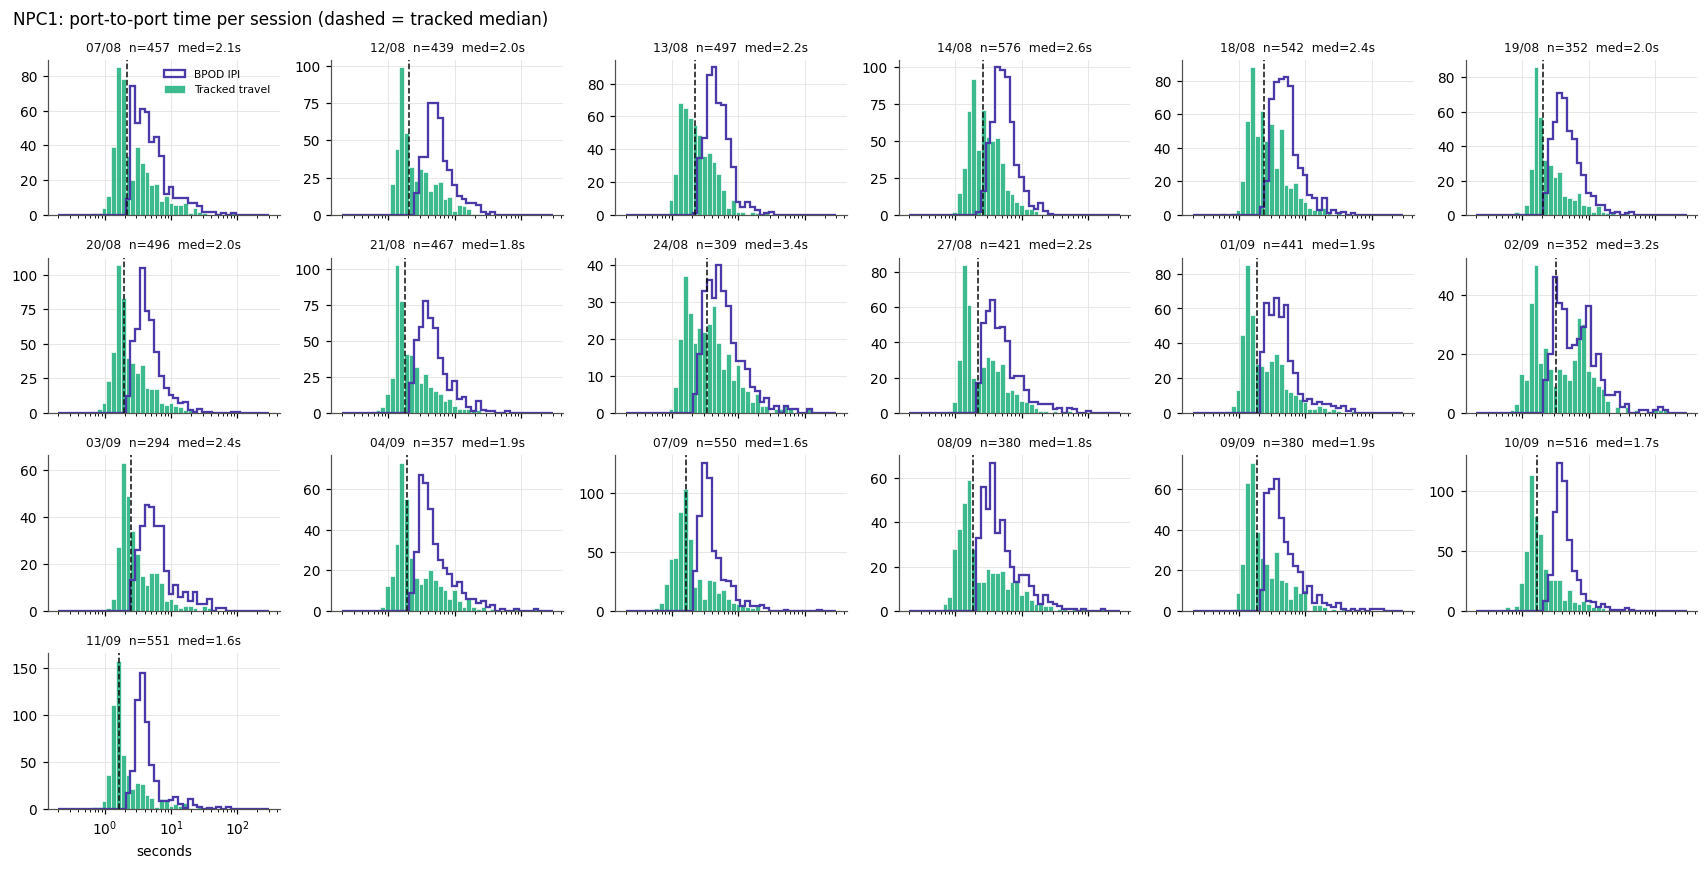

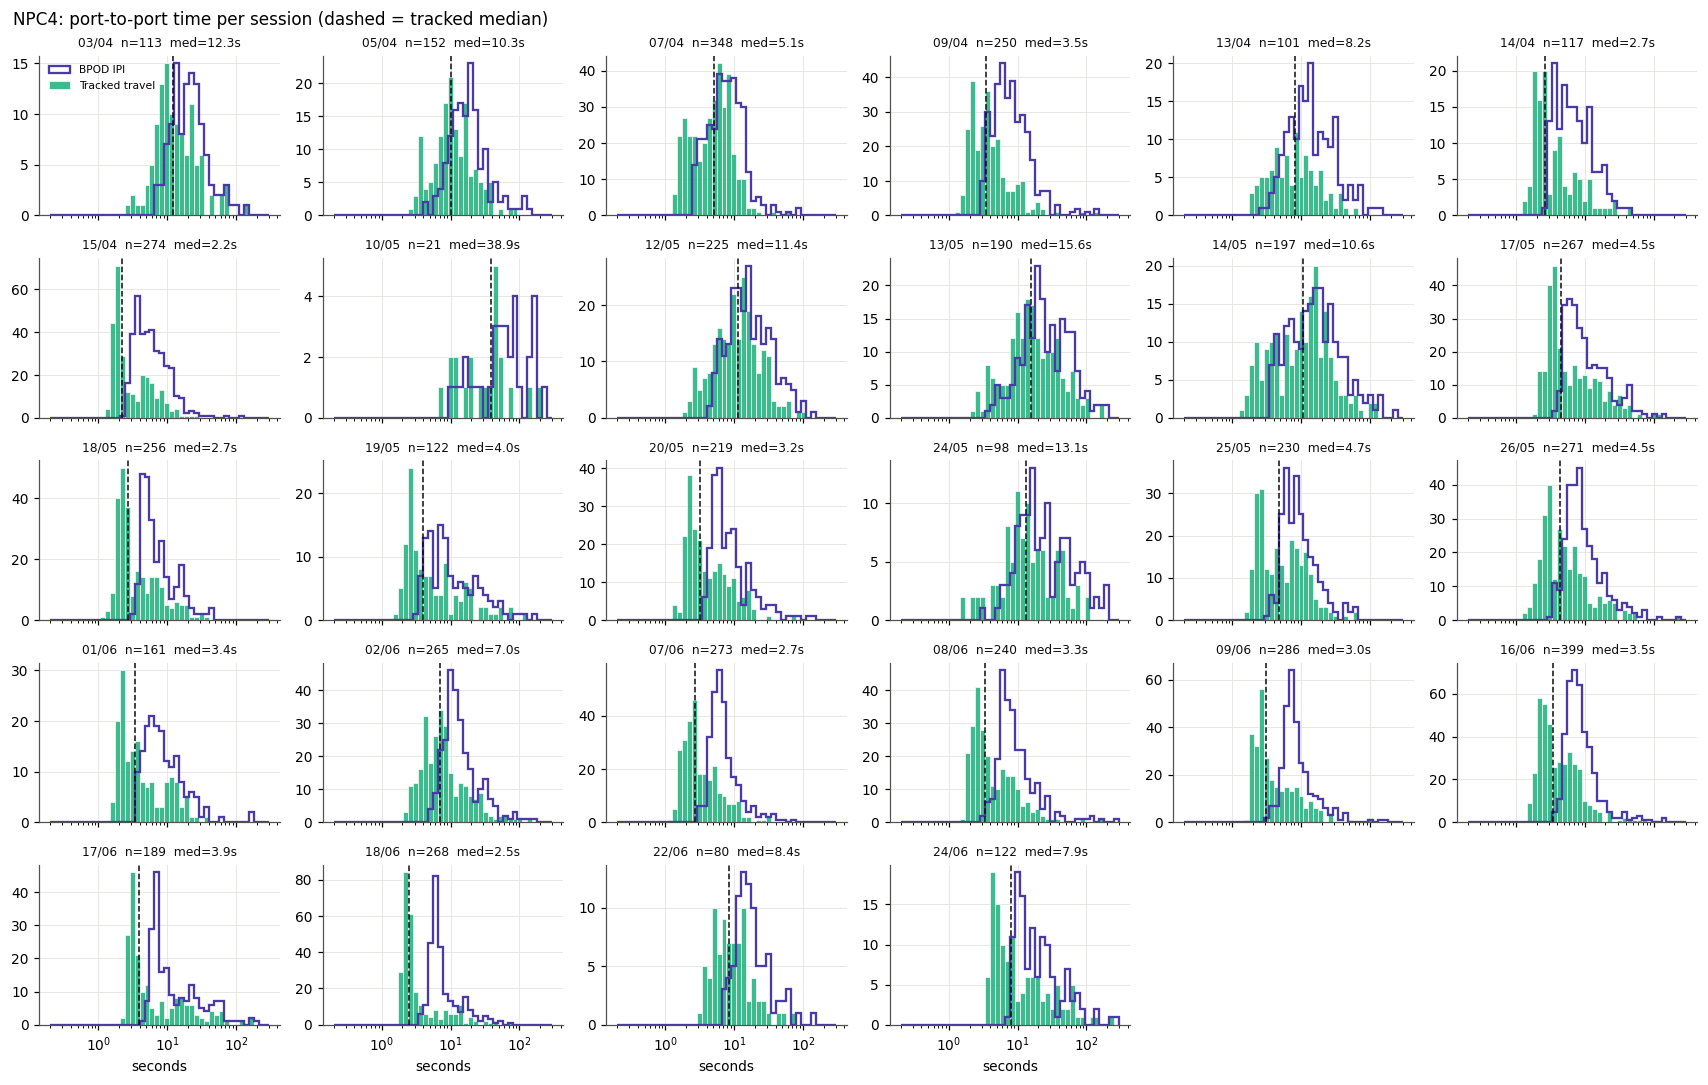

In [7]:
BINS = np.logspace(np.log10(0.2), np.log10(300), 45)


def session_grid(subject, ncols=6):
    sess = qc[qc['subject'] == subject]
    n = len(sess)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.0 * nrows), sharex=True, squeeze=False)
    for ax, (_, s) in zip(axes.flat, sess.iterrows()):
        d = p2p[(p2p['subject'] == subject) & (p2p['session'] == s['session'])]
        ipi = trials[(trials['subject'] == subject) & (trials['session'] == s['session'])
                     & trials['port_from'].notna() & (trials['port_from'] != trials['port_to'])]['bpod_ipi_s']
        ax.hist(ipi, bins=BINS, histtype='step', lw=1.5, color=BPOD_COLOR, label='BPOD IPI')
        ax.hist(d['travel_s'], bins=BINS, color=TRACK_COLOR, alpha=0.85, label='Tracked travel',
                edgecolor='white', linewidth=0.5)
        med = d['travel_s'].median()
        ax.axvline(med, color=INK, lw=1, ls='--')
        ax.set_xscale('log')
        ax.set_title(f"{s['label']}  n={len(d)}  med={med:.1f}s", fontsize=8, color=INK)
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel('seconds')
    axes[0, 0].legend(fontsize=7, frameon=False)
    fig.suptitle(f'{subject}: port-to-port time per session (dashed = tracked median)', fontsize=11, x=0.01, ha='left')
    fig.tight_layout()
    return fig


for subj in SUBJECTS:
    fig = session_grid(subj)
    fig.savefig(QC_DIR / f'{subj}_p2p_time_per_session.png', dpi=150, bbox_inches='tight')
    plt.show()

### 3.2 Every session, split by port pair

One page per session with one box per ordered port pair, sorted by graph
distance and annotated with *n*. Every session is written to a multi-page PDF
per subject, and a single example session is shown inline. Change `SHOW` to look
at a different one.

Saved /var/home/almogmeir/Documents/GitHub/NaviGraph/examples/dual_root_tree/resources/outputs/tracking_validation/NPC1_p2p_time_by_pair_per_session.pdf
Saved /var/home/almogmeir/Documents/GitHub/NaviGraph/examples/dual_root_tree/resources/outputs/tracking_validation/NPC4_p2p_time_by_pair_per_session.pdf


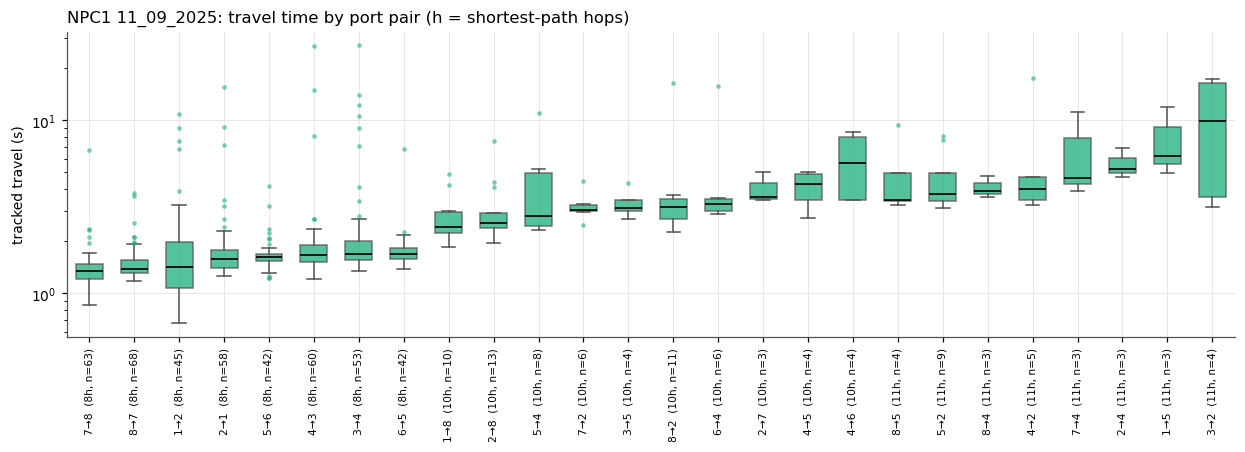

In [8]:
MIN_N_PAIR = 3   # hide pairs with fewer timed trials than this


def plot_session_pairs(subject, session, ax=None):
    d = p2p[(p2p['subject'] == subject) & (p2p['session'] == session)]
    order = (d.groupby('pair').agg(n=('travel_s', 'size'), hops=('sp_hops', 'first'), med=('travel_s', 'median'))
               .query('n >= @MIN_N_PAIR').sort_values(['hops', 'med']))
    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(order) + 2), 3.6))
    if order.empty:
        ax.text(0.5, 0.5, 'no pair with enough timed trials', ha='center', transform=ax.transAxes)
        return ax
    data = [d.loc[d['pair'] == p, 'travel_s'].to_numpy() for p in order.index]
    bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=True,
                    flierprops=dict(marker='o', ms=3, mfc=TRACK_COLOR, mec='none', alpha=0.6),
                    medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=INK2),
                    capprops=dict(color=INK2), boxprops=dict(edgecolor=INK2))
    for b in bp['boxes']:
        b.set_facecolor(TRACK_COLOR); b.set_alpha(0.75)
    ax.set_yscale('log')
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([f"{p}  ({int(h)}h, n={n})" for p, h, n in zip(order.index, order['hops'], order['n'])],
                       fontsize=7, rotation=90)
    ax.set_ylabel('tracked travel (s)')
    ax.set_title(f'{subject} {session}: travel time by port pair (h = shortest-path hops)', loc='left')
    return ax


for subj in SUBJECTS:
    with PdfPages(QC_DIR / f'{subj}_p2p_time_by_pair_per_session.pdf') as pdf:
        for sess in qc.loc[qc['subject'] == subj, 'session']:
            ax = plot_session_pairs(subj, sess)
            pdf.savefig(ax.figure, bbox_inches='tight'); plt.close(ax.figure)
    print('Saved', QC_DIR / f'{subj}_p2p_time_by_pair_per_session.pdf')

SHOW = (SUBJECTS[0], qc.loc[qc['subject'] == SUBJECTS[0], 'session'].iloc[-1])
plot_session_pairs(*SHOW); plt.show()

### 3.3 Per-session summary table

Travel-time quantiles for each session, alongside the BPOD IPI median.

In [9]:
def q(p):
    f = lambda x: x.quantile(p)
    f.__name__ = f'p{int(p * 100)}'
    return f


sess_summary = (p2p.groupby(['subject', 'date', 'session'])['travel_s']
                  .agg(n='size', median='median', p5=q(0.05), p25=q(0.25), p75=q(0.75), p95=q(0.95), mean='mean')
                  .join(p2p.groupby(['subject', 'date', 'session'])['bpod_ipi_s'].median().rename('bpod_ipi_median'))
                  .join(p2p.groupby(['subject', 'date', 'session'])['sec_per_hop'].median().rename('sec_per_hop_median'))
                  .reset_index().drop(columns='date').round(2))
sess_summary.to_csv(QC_DIR / 'p2p_time_per_session.csv', index=False)
display(sess_summary)

,subject,session,n,median,p5,p25,p75,p95,mean,bpod_ipi_median,sec_per_hop_median
0,NPC1,07_08_2025,457,2.15,1.30,1.65,4.00,12.37,4.04,4.33,0.35
1,NPC1,12_08_2025,439,2.02,1.25,1.58,3.82,9.08,3.35,5.26,0.34
2,NPC1,13_08_2025,497,2.20,1.20,1.55,3.45,5.93,2.86,4.64,0.35
3,NPC1,14_08_2025,576,2.62,1.34,1.82,4.03,7.75,3.33,5.20,0.39
4,NPC1,18_08_2025,542,2.35,1.25,1.62,4.04,8.67,3.38,4.92,0.34
5,NPC1,19_08_2025,352,2.02,1.34,1.62,3.43,8.95,3.25,4.28,0.33
6,NPC1,20_08_2025,496,1.98,1.18,1.60,3.36,8.83,3.25,4.15,0.32
7,NPC1,21_08_2025,467,1.80,1.10,1.40,3.11,8.33,2.90,4.24,0.29
8,NPC1,24_08_2025,309,3.35,1.34,1.82,5.72,16.12,5.79,5.36,0.46
9,NPC1,27_08_2025,421,2.20,1.18,1.42,4.15,10.10,3.55,4.28,0.32


### 3.4 Subject summary: all sessions pooled

- **Left:** pooled tracked travel-time distribution for each subject.
- **Middle:** seconds per hop (travel time ÷ shortest-path hops). Dividing out
  distance puts long and short pairs on one scale.
- **Right:** median travel time per session over the experiment, split by
  shortest-path distance (short ≤ median hops, long > median). A learning trend
  should look smooth, so an isolated jump on one session points to a tracking
  problem in that session.

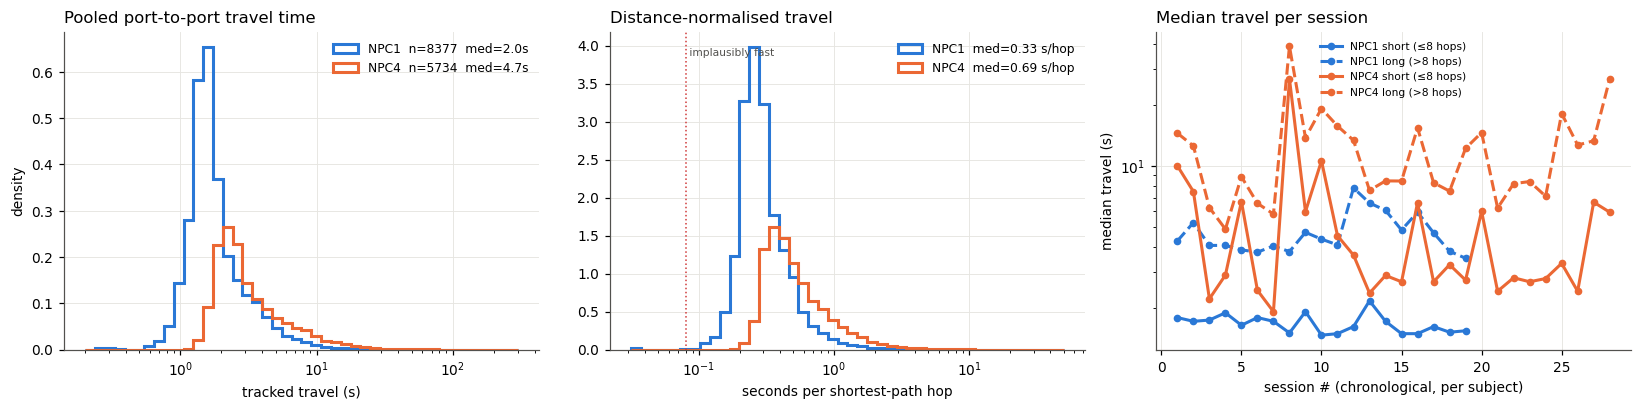

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for subj in SUBJECTS:
    d = p2p[p2p['subject'] == subj]
    c = SUBJECT_COLOR[subj]
    axes[0].hist(d['travel_s'], bins=BINS, histtype='step', lw=2, color=c, density=True,
                 label=f"{subj}  n={len(d)}  med={d['travel_s'].median():.1f}s")
    axes[1].hist(d['sec_per_hop'], bins=np.logspace(-1.5, 1.7, 45), histtype='step', lw=2, color=c, density=True,
                 label=f"{subj}  med={d['sec_per_hop'].median():.2f} s/hop")
axes[0].set_xscale('log'); axes[0].set_xlabel('tracked travel (s)'); axes[0].set_ylabel('density')
axes[0].set_title('Pooled port-to-port travel time', loc='left'); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xscale('log'); axes[1].set_xlabel('seconds per shortest-path hop')
axes[1].axvline(MIN_SEC_PER_HOP, color=STATUS_COLOR['fail'], lw=1, ls=':')
axes[1].text(MIN_SEC_PER_HOP, axes[1].get_ylim()[1] * 0.95, ' implausibly fast', color=INK2, fontsize=7, va='top')
axes[1].set_title('Distance-normalised travel', loc='left'); axes[1].legend(frameon=False, fontsize=8)

hop_split = p2p['sp_hops'].median()
for subj in SUBJECTS:
    d = p2p[p2p['subject'] == subj]
    sess_no = {dt: i + 1 for i, dt in enumerate(sorted(d['date'].unique()))}
    for long_, ls in [(False, '-'), (True, '--')]:
        m = d[(d['sp_hops'] > hop_split) == long_].groupby('date')['travel_s'].median()
        axes[2].plot([sess_no[t] for t in m.index], m.values, ls, marker='o', ms=4, lw=2, color=SUBJECT_COLOR[subj],
                     label=f"{subj} {'long' if long_ else 'short'} ({'>' if long_ else '≤'}{hop_split:.0f} hops)")
axes[2].set_xlabel('session # (chronological, per subject)'); axes[2].set_yscale('log')
axes[2].set_ylabel('median travel (s)'); axes[2].set_title('Median travel per session', loc='left')
axes[2].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(QC_DIR / 'p2p_subject_summary.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.5 Subject summary by port pair

Median tracked travel time per ordered port pair, pooled over every session of
the subject (rows = from, columns = to). The second table lists *n*, median, IQR
and the 5th/95th percentiles for each pair. Port numbers are BPOD numbers,
so the same number can sit on a different leaf in different layout periods.

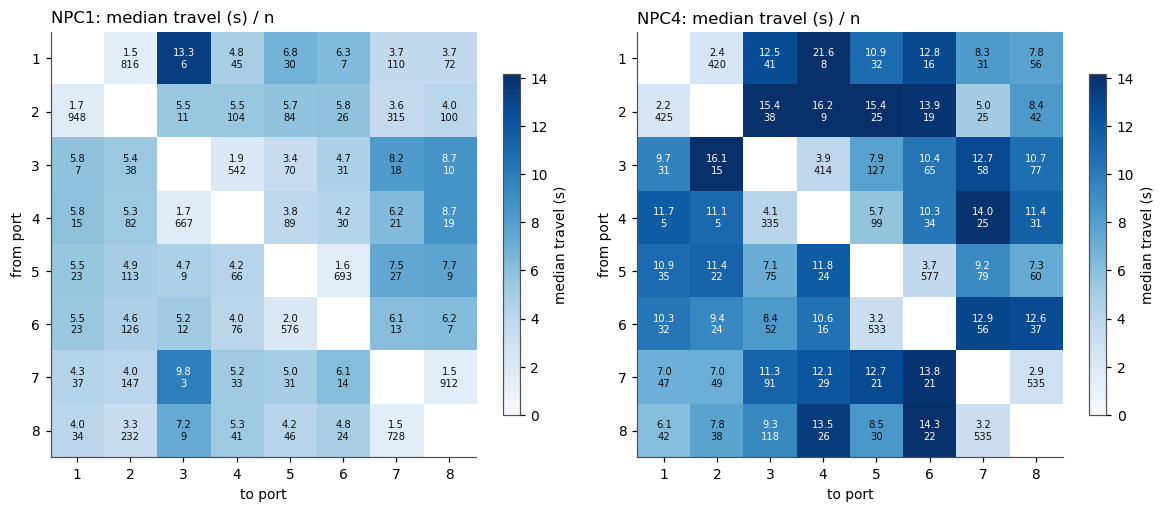


NPC1: top 15 port pairs by count


,subject,pair,n,n_sessions,sp_hops,median,p25,p75,p5,p95,bpod_ipi_median
7,NPC1,2→1,948,19,8.0,1.70,1.48,2.17,1.26,4.45,3.85
48,NPC1,7→8,912,19,8.0,1.52,1.27,1.92,1.00,3.39,3.51
0,NPC1,1→2,816,19,8.0,1.52,1.27,1.88,1.02,8.95,3.41
55,NPC1,8→7,728,19,8.0,1.50,1.25,1.95,0.95,4.30,3.78
32,NPC1,5→6,693,19,8.0,1.62,1.45,2.05,1.18,5.07,4.26
23,NPC1,4→3,667,19,8.0,1.68,1.48,1.95,1.25,3.69,3.76
39,NPC1,6→5,576,19,8.0,2.02,1.58,2.78,0.95,5.03,3.92
16,NPC1,3→4,542,18,8.0,1.95,1.70,2.52,1.40,6.86,3.78
12,NPC1,2→7,315,18,10.0,3.58,2.76,5.30,2.24,11.23,5.58
50,NPC1,8→2,232,19,10.0,3.30,2.82,4.25,2.29,10.03,5.16



NPC4: top 15 port pairs by count


,subject,pair,n,n_sessions,sp_hops,median,p25,p75,p5,p95,bpod_ipi_median
88,NPC4,5→6,577,25,8.0,3.70,2.75,6.15,2.10,22.90,7.11
104,NPC4,7→8,535,27,8.0,2.92,2.22,5.30,1.87,14.69,6.97
111,NPC4,8→7,535,27,8.0,3.18,2.50,5.59,1.92,16.68,6.91
95,NPC4,6→5,533,25,8.0,3.20,2.62,4.88,1.92,18.91,6.47
63,NPC4,2→1,425,23,8.0,2.25,1.98,3.08,1.70,7.88,6.41
56,NPC4,1→2,420,22,8.0,2.38,1.95,3.21,1.50,9.43,6.69
72,NPC4,3→4,414,27,8.0,3.89,2.20,8.38,1.60,28.69,8.61
79,NPC4,4→3,335,26,8.0,4.10,2.31,8.12,1.70,23.82,8.32
73,NPC4,3→5,127,25,10.0,7.88,4.44,12.90,3.14,43.68,12.20
107,NPC4,8→3,118,19,11.0,9.31,7.36,13.87,4.94,31.09,13.43


In [11]:
fig, axes = plt.subplots(1, len(SUBJECTS), figsize=(5.4 * len(SUBJECTS), 4.4))
for ax, subj in zip(np.atleast_1d(axes), SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    mat = d.pivot_table(index='port_from', columns='port_to', values='travel_s', aggfunc='median')
    cnt = d.pivot_table(index='port_from', columns='port_to', values='travel_s', aggfunc='size')
    mat = mat.reindex(index=range(1, 9), columns=range(1, 9))
    cnt = cnt.reindex(index=range(1, 9), columns=range(1, 9))
    im = ax.imshow(mat.values, cmap='Blues', vmin=0, vmax=np.nanpercentile(p2p.groupby(['subject', 'pair'])['travel_s'].median(), 95))
    for i in range(8):
        for j in range(8):
            v, n = mat.values[i, j], cnt.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f'{v:.1f}\n{int(n)}', ha='center', va='center', fontsize=6.5,
                        color='white' if v > im.get_clim()[1] * 0.6 else INK)
    ax.set_xticks(range(8)); ax.set_xticklabels(range(1, 9)); ax.set_yticks(range(8)); ax.set_yticklabels(range(1, 9))
    ax.set_xlabel('to port'); ax.set_ylabel('from port'); ax.grid(False)
    ax.set_title(f'{subj}: median travel (s) / n', loc='left')
    fig.colorbar(im, ax=ax, shrink=0.8, label='median travel (s)')
fig.tight_layout()
fig.savefig(QC_DIR / 'p2p_pair_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

pair_summary = (p2p.groupby(['subject', 'pair'])
                  .agg(n=('travel_s', 'size'), n_sessions=('session', 'nunique'), sp_hops=('sp_hops', 'median'),
                       median=('travel_s', 'median'), p25=('travel_s', q(0.25)), p75=('travel_s', q(0.75)),
                       p5=('travel_s', q(0.05)), p95=('travel_s', q(0.95)),
                       bpod_ipi_median=('bpod_ipi_s', 'median'))
                  .reset_index().sort_values(['subject', 'n'], ascending=[True, False]).round(2))
pair_summary.to_csv(QC_DIR / 'p2p_time_per_pair_subject.csv', index=False)
for subj in SUBJECTS:
    print(f'\n{subj}: top 15 port pairs by count')
    display(pair_summary[pair_summary['subject'] == subj].head(15))

### 3.6 Session-to-session consistency of the common pairs

For each subject's 8 most frequent pairs: median travel per session, with IQR
bars. A single session far off its neighbours on *every* pair suggests a
tracking or alignment problem. Drift on one pair only is more likely behavioural.

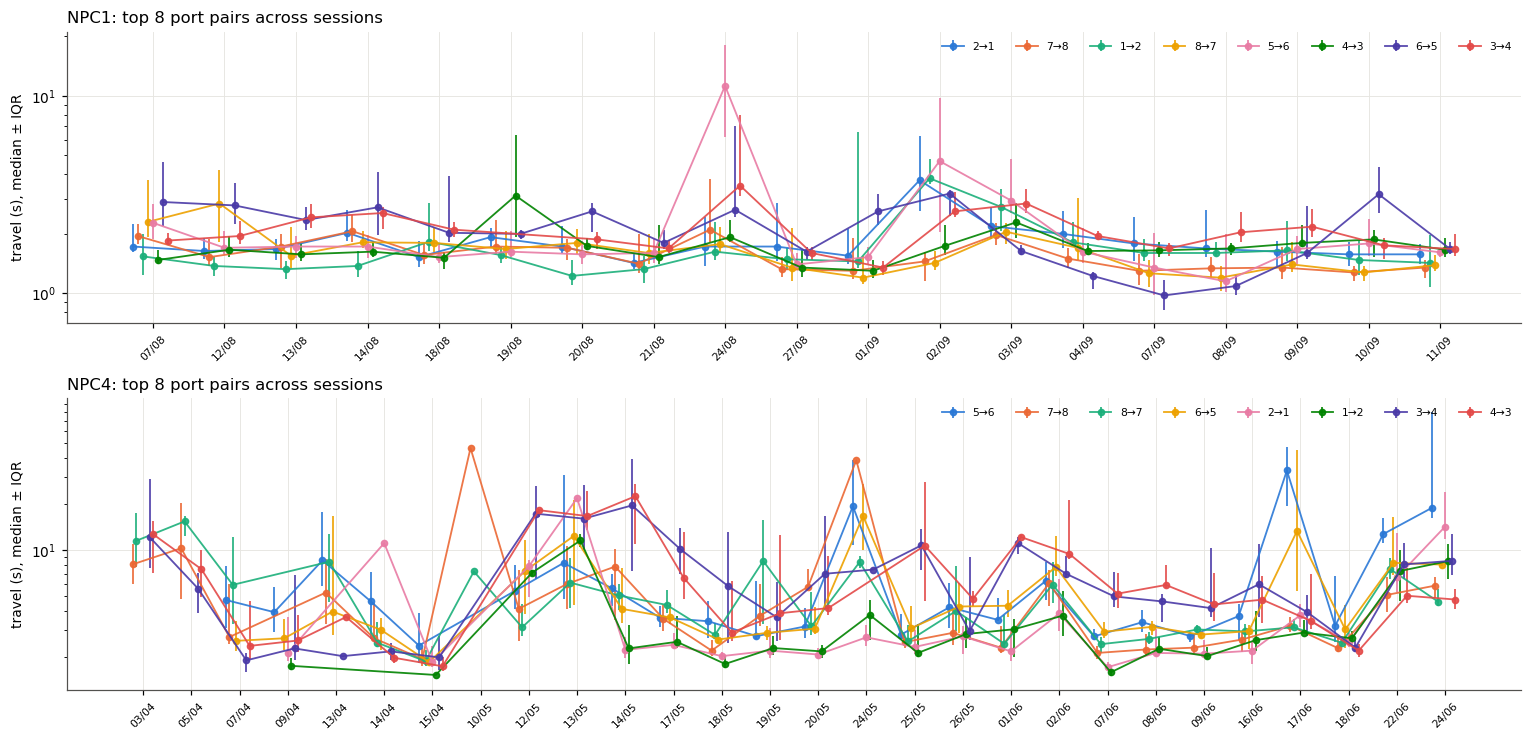

In [12]:
TOP_K = 8
fig, axes = plt.subplots(len(SUBJECTS), 1, figsize=(14, 3.4 * len(SUBJECTS)), squeeze=False)
for ax, subj in zip(axes[:, 0], SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    top = d['pair'].value_counts().head(TOP_K).index
    labels = qc.loc[qc['subject'] == subj, ['date', 'label']].drop_duplicates()
    xpos = {dt: i for i, dt in enumerate(labels['date'])}
    cmap = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
    for k, pair in enumerate(top):
        g = d[d['pair'] == pair].groupby('date')['travel_s']
        med, lo, hi = g.median(), g.quantile(0.25), g.quantile(0.75)
        x = np.array([xpos[t] for t in med.index]) + (k - TOP_K / 2) * 0.07
        ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt='o-', ms=4, lw=1.2, capsize=0,
                    color=cmap[k], label=pair, alpha=0.9)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels['label'], rotation=45, fontsize=7)
    ax.set_yscale('log'); ax.set_ylabel('travel (s), median ± IQR')
    ax.set_title(f'{subj}: top {TOP_K} port pairs across sessions', loc='left')
    ax.legend(ncol=TOP_K, fontsize=7, frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(QC_DIR / 'p2p_top_pairs_across_sessions.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Validations

Each check reads from the per-session `qc` table built in Section 2, so the plots
below and the scorecard in Section 5 always agree.

In [13]:
def session_bars(ax, col, title, ylabel, thresholds=None, fmt='{:.0f}'):
    """Bars per session, grouped by subject; optional (fail, warn) threshold lines."""
    x0 = 0
    ticks, labels = [], []
    for subj in SUBJECTS:
        d = qc[qc['subject'] == subj]
        xs = np.arange(x0, x0 + len(d))
        ax.bar(xs, d[col], color=SUBJECT_COLOR[subj], width=0.8, label=subj)
        ticks += list(xs); labels += list(d['label'])
        x0 += len(d) + 1.5
    if thresholds:
        for v, k in zip(thresholds, ['fail', 'warn']):
            if v is not None:
                ax.axhline(v, color=STATUS_COLOR[k], lw=1, ls='--')
                ax.text(ax.get_xlim()[1], v, f' {k} {fmt.format(v)}', color=INK2, fontsize=7, va='center')
    ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=90, fontsize=6.5)
    ax.set_title(title, loc='left'); ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(1.0, 0.0))

### 4.1 Coverage

How much of each BPOD session has video, and how much of the video has a graph
location.
- A low *in-video* fraction means the camera started late or stopped early (the
  pipeline trims those trials).
- *Unlocated frames* have neither a node nor an edge: the DLC point fell
  outside every mapped region.

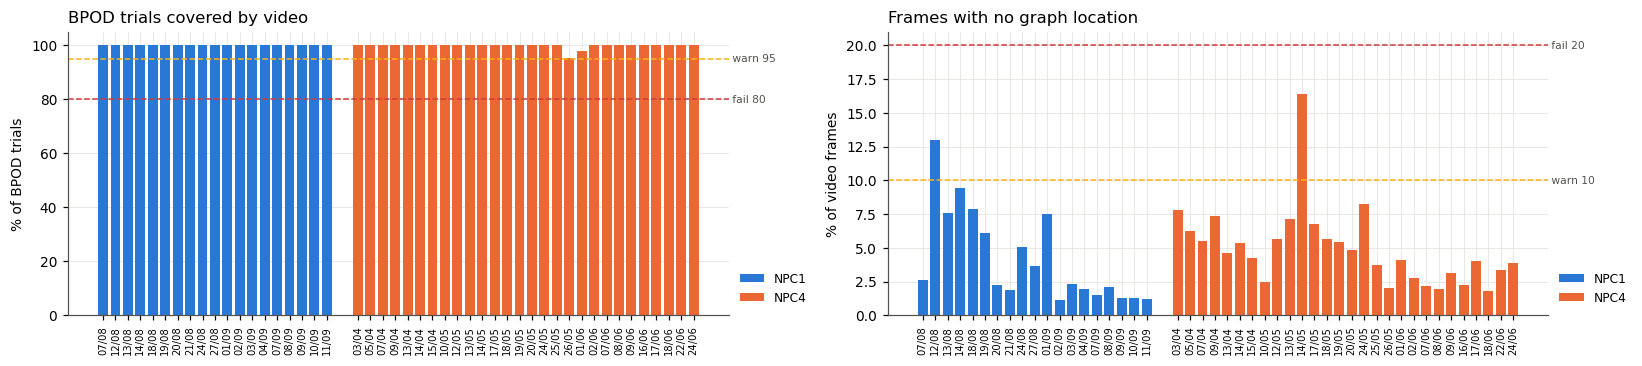

,subject,session,n_bpod_trials,n_trials_in_video,n_trials_tracked,first_tracked_trial,video_min,pct_frames_unlocated
0,NPC1,07_08_2025,620,620,620,0,62.0,2.6
1,NPC1,12_08_2025,814,814,787,0,77.0,13.0
2,NPC1,13_08_2025,754,754,752,0,64.4,7.6
3,NPC1,14_08_2025,935,935,918,0,85.1,9.4
4,NPC1,18_08_2025,706,706,702,0,66.5,7.9
5,NPC1,19_08_2025,628,628,626,0,57.3,6.1
6,NPC1,20_08_2025,676,676,676,0,60.2,2.2
7,NPC1,21_08_2025,647,647,647,0,57.8,1.9
8,NPC1,24_08_2025,383,383,383,0,47.7,5.1
9,NPC1,27_08_2025,541,541,541,0,57.1,3.7


In [14]:
qc['pct_trials_in_video'] = 100 * qc['n_trials_in_video'] / qc['n_bpod_trials']
fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
session_bars(axes[0], 'pct_trials_in_video', 'BPOD trials covered by video', '% of BPOD trials', thresholds=(80, 95))
session_bars(axes[1], 'pct_frames_unlocated', 'Frames with no graph location', '% of video frames',
             thresholds=(20, 10))
fig.tight_layout(); plt.show()
display(qc[['subject', 'session', 'n_bpod_trials', 'n_trials_in_video', 'n_trials_tracked',
            'first_tracked_trial', 'video_min', 'pct_frames_unlocated']].round(1))

### 4.2 Reward-on-port

- **On port at poke:** at the BPOD poke frame, the tracked node is the paying
  port's leaf or its parent. This is the same metric `session_pipeline.ipynb`
  uses to accept the clock alignment (≥ 60 %).
- **Leaf within ±1 s:** a stricter version that requires an actual visit to the
  port leaf within `POKE_WINDOW_S` of the poke. The port-to-port timing depends
  on it. This check is informational: with `PORT_ZONE = 'leaf+parent'` the
  timing doesn't require a leaf visit.

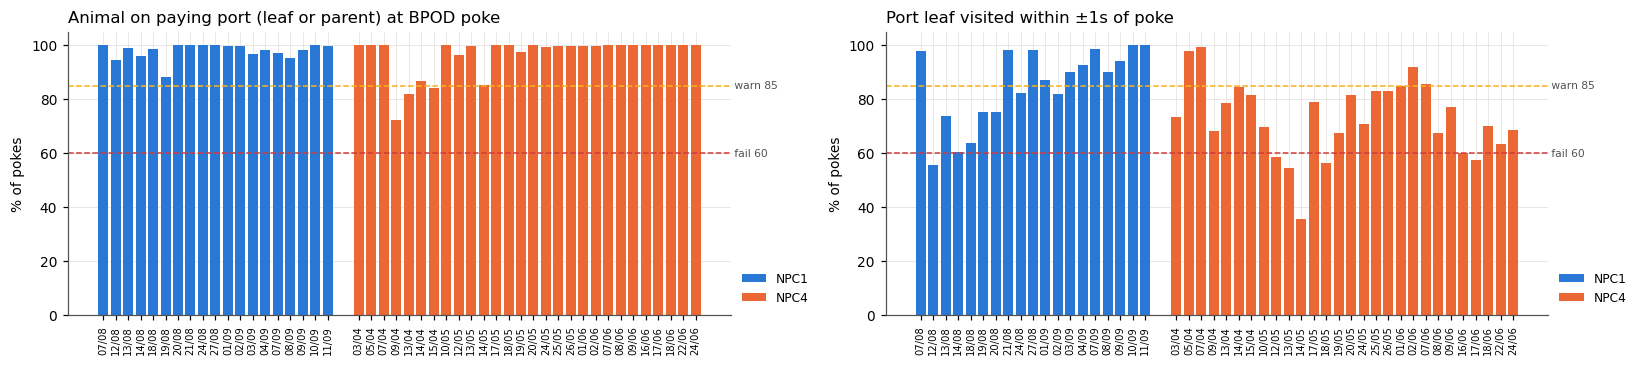

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
session_bars(axes[0], 'on_port_pct', 'Animal on paying port (leaf or parent) at BPOD poke', '% of pokes',
             thresholds=(MIN_ON_PORT_PCT, WARN_ON_PORT_PCT))
session_bars(axes[1], 'leaf_within_window_pct', f'Port leaf visited within ±{POKE_WINDOW_S:g}s of poke', '% of pokes',
             thresholds=(MIN_ON_PORT_PCT, WARN_ON_PORT_PCT))
for ax in axes: ax.set_ylim(0, 105)
fig.tight_layout(); plt.show()

### 4.3 Residual clock offset and drift

The pipeline corrects a constant camera-start offset. This check looks for what
is left over: for each session we shift every poke frame by −5 s…+5 s and find
the shift that maximises the on-port %.
- With a correct alignment the best shift is near 0.
- A non-zero shift that is the **same in both halves** is a residual constant
  offset.
- A **difference between the halves** means the two clocks drift apart during
  the session (a frame-rate mismatch or dropped frames), which a single offset
  cannot fix.

The animal is usually on the port a little before the poke and leaves soon
after, so a small negative shift (−0.1 to −0.3 s) is expected behaviour rather than
a clock error. Look for values beyond ±0.5 s, or halves that disagree.

The *latency slope* is a second drift estimate: the linear trend of the poke
latency (§4.4) over session time, in seconds per hour.

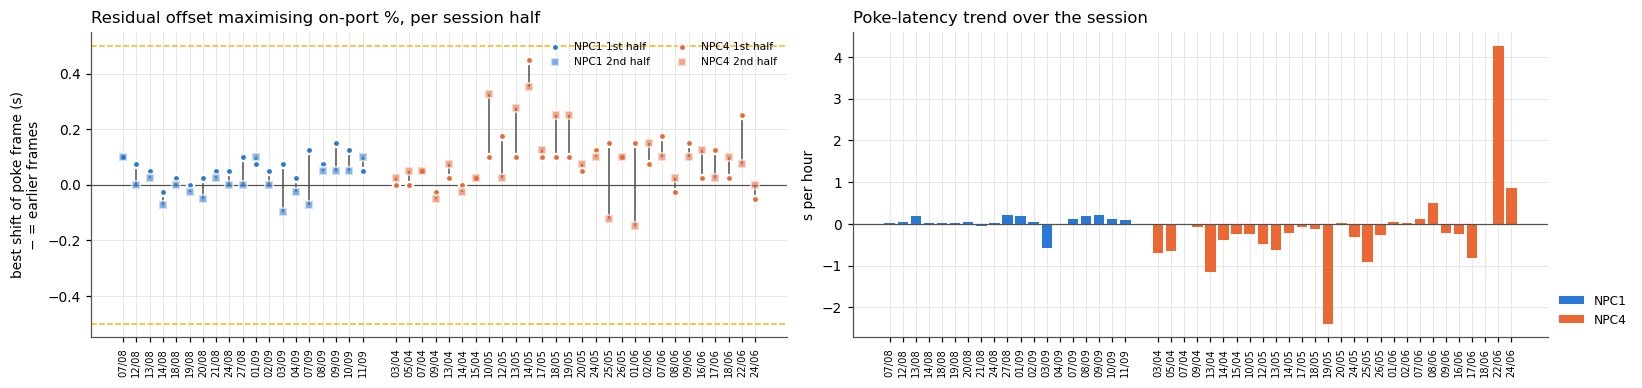

,subject,session,resid_shift_s,resid_shift_first_half_s,resid_shift_second_half_s,latency_drift_s_per_h
0,NPC1,07_08_2025,0.10,0.10,0.10,0.03
1,NPC1,12_08_2025,0.05,0.08,0.00,0.04
2,NPC1,13_08_2025,0.05,0.05,0.02,0.20
3,NPC1,14_08_2025,-0.02,-0.02,-0.08,0.03
4,NPC1,18_08_2025,0.02,0.02,0.00,0.02
5,NPC1,19_08_2025,0.00,0.00,-0.02,0.02
6,NPC1,20_08_2025,0.02,0.02,-0.05,0.04
7,NPC1,21_08_2025,0.05,0.05,0.02,-0.04
8,NPC1,24_08_2025,0.08,0.05,0.00,0.02
9,NPC1,27_08_2025,0.05,0.10,0.00,0.21


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
x0 = 0; ticks = []; labels = []
for subj in SUBJECTS:
    d = qc[qc['subject'] == subj]
    xs = np.arange(x0, x0 + len(d))
    axes[0].vlines(xs, d['resid_shift_first_half_s'], d['resid_shift_second_half_s'], color=INK2, lw=1)
    axes[0].scatter(xs, d['resid_shift_first_half_s'], s=22, color=SUBJECT_COLOR[subj], marker='o',
                    edgecolor='white', linewidth=1.5, label=f'{subj} 1st half', zorder=3)
    axes[0].scatter(xs, d['resid_shift_second_half_s'], s=26, color=SUBJECT_COLOR[subj], marker='s',
                    edgecolor='white', linewidth=1.5, label=f'{subj} 2nd half', zorder=3, alpha=0.6)
    ticks += list(xs); labels += list(d['label']); x0 += len(d) + 1.5
for v in (-MAX_RESID_SHIFT_S, MAX_RESID_SHIFT_S):
    axes[0].axhline(v, color=STATUS_COLOR['warn'], lw=1, ls='--')
axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set_xticks(ticks); axes[0].set_xticklabels(labels, rotation=90, fontsize=6.5)
axes[0].set_ylabel('best shift of poke frame (s)\n− = earlier frames')
axes[0].set_title('Residual offset maximising on-port %, per session half', loc='left')
axes[0].legend(frameon=False, fontsize=7, ncol=2)
session_bars(axes[1], 'latency_drift_s_per_h', 'Poke-latency trend over the session', 's per hour',
             thresholds=None)
axes[1].axhline(0, color=INK2, lw=0.8)
fig.tight_layout(); plt.show()

display(qc[['subject', 'session', 'resid_shift_s', 'resid_shift_first_half_s', 'resid_shift_second_half_s',
            'latency_drift_s_per_h']].round(2))

### 4.4 Poke latency

The time from the tracked arrival at port B's leaf to BPOD's poke at B.
Physically it should be small and non-negative: the animal reaches the port,
then pokes. A wide spread or a negative bulk means the tracked arrival and the
sensor event disagree.

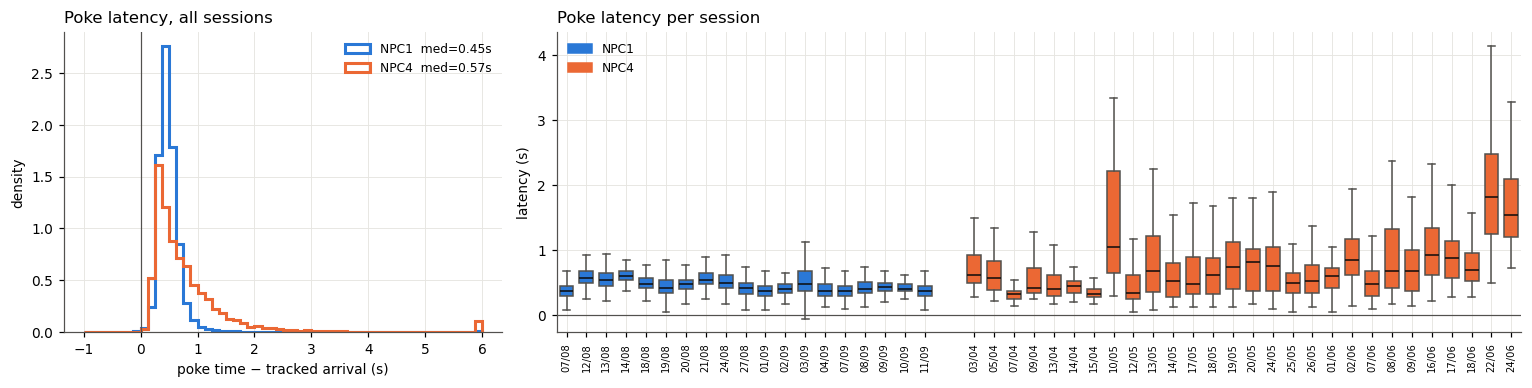

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [1, 2.2]})
lat_bins = np.linspace(-POKE_WINDOW_S, 6, 57)
for subj in SUBJECTS:
    d = p2p[p2p['subject'] == subj]['poke_latency_s']
    axes[0].hist(d.clip(upper=6), bins=lat_bins, histtype='step', lw=2, color=SUBJECT_COLOR[subj], density=True,
                 label=f'{subj}  med={d.median():.2f}s')
axes[0].axvline(0, color=INK2, lw=0.8)
axes[0].set_xlabel('poke time − tracked arrival (s)'); axes[0].set_ylabel('density')
axes[0].set_title('Poke latency, all sessions', loc='left'); axes[0].legend(frameon=False, fontsize=8)

pos = 0; ticks = []; labels = []
for subj in SUBJECTS:
    for _, s in qc[qc['subject'] == subj].iterrows():
        d = p2p[(p2p['subject'] == subj) & (p2p['session'] == s['session'])]['poke_latency_s'].clip(upper=6)
        if len(d):
            b = axes[1].boxplot([d], positions=[pos], widths=0.7, patch_artist=True, showfliers=False,
                                medianprops=dict(color=INK), boxprops=dict(edgecolor=INK2),
                                whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
            b['boxes'][0].set_facecolor(SUBJECT_COLOR[subj])
        ticks.append(pos); labels.append(s['label']); pos += 1
    pos += 1.5
axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].set_xticks(ticks); axes[1].set_xticklabels(labels, rotation=90, fontsize=6.5)
axes[1].set_ylabel('latency (s)'); axes[1].set_title('Poke latency per session', loc='left')
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SUBJECT_COLOR[s_]) for s_ in SUBJECTS], labels=SUBJECTS,
               frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); plt.show()

### 4.5 Tracked travel vs BPOD inter-poke interval

The IPI is poke(A) → poke(B), and the tracked travel is leave(A) → reach(B),
which sits inside that window. A tracked travel **longer** than the IPI (beyond a
0.25 s tolerance) is impossible, so the depart/arrive matching picked the wrong
run. Points should fall below the diagonal.

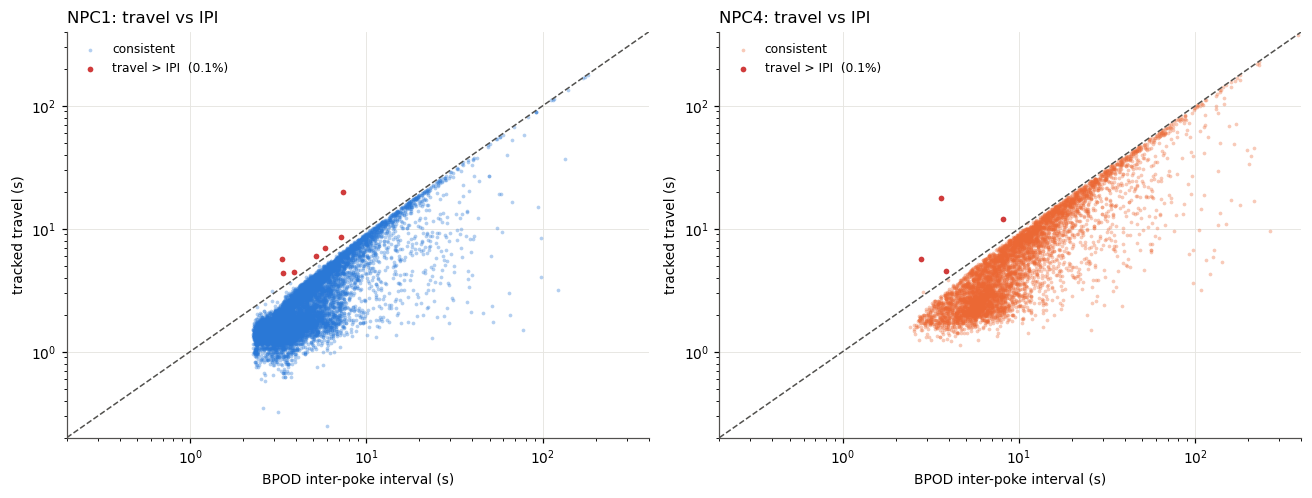

In [18]:
fig, axes = plt.subplots(1, len(SUBJECTS), figsize=(6 * len(SUBJECTS), 4.6), squeeze=False)
for ax, subj in zip(axes[0], SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    bad = d['travel_s'] > d['bpod_ipi_s'] + 0.25
    ax.scatter(d.loc[~bad, 'bpod_ipi_s'], d.loc[~bad, 'travel_s'], s=6, color=SUBJECT_COLOR[subj],
               alpha=0.35, linewidths=0, label='consistent')
    ax.scatter(d.loc[bad, 'bpod_ipi_s'], d.loc[bad, 'travel_s'], s=14, color=STATUS_COLOR['fail'],
               linewidths=0, label=f'travel > IPI  ({bad.mean() * 100:.1f}%)')
    lim = [0.2, 400]
    ax.plot(lim, lim, color=INK2, lw=1, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('BPOD inter-poke interval (s)'); ax.set_ylabel('tracked travel (s)')
    ax.set_title(f'{subj}: travel vs IPI', loc='left'); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

### 4.6 Physical plausibility

- **Too fast:** seconds per hop below `MIN_SEC_PER_HOP`. The animal can't cover
  that many corridors that quickly, so either an arrival was detected early or a
  departure late.
- **Shorter than the shortest path:** the tracked node path between the two
  ports has fewer hops than the graph shortest path. On a tree that is
  impossible, so nodes were skipped and the traversal fixer didn't fill them.
- **Path ratio:** tracked hops ÷ shortest hops. 1.0 is a direct run, and values
  below 1 belong to the previous point.

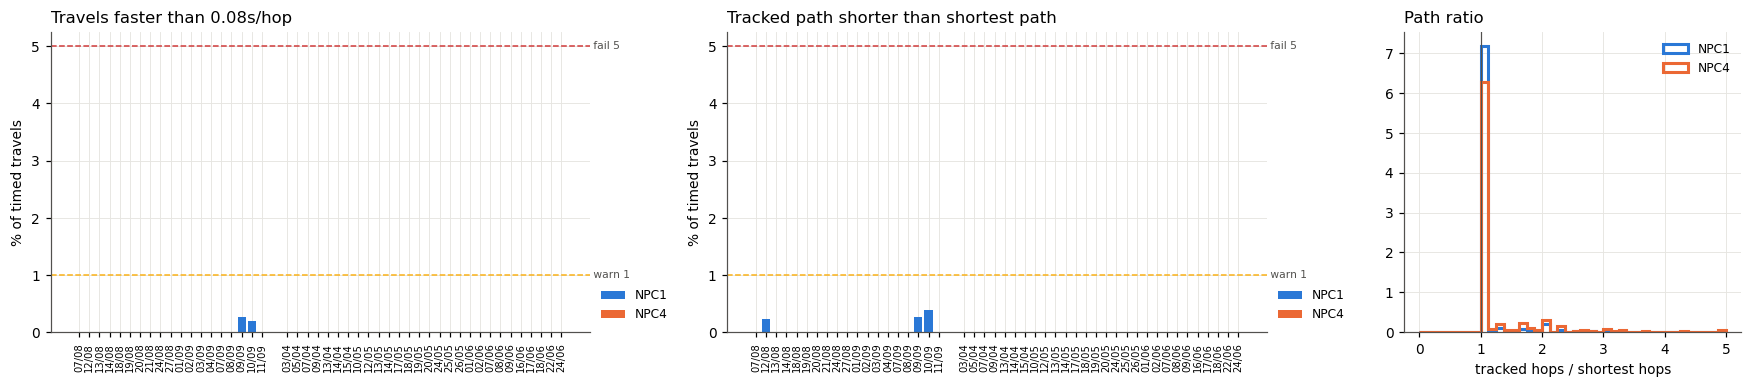

Worst offenders: tracked path shorter than the shortest path


,subject,session,trial_idx,pair,endpoint_sp_hops,tracked_hops,travel_s,n_inferred,n_illegal
10239,NPC1,09_09_2025,308,7→5,10.0,1.0,0.125,2.0,1.0
10986,NPC1,10_09_2025,547,6→5,7.0,1.0,0.250,2.0,1.0
11009,NPC1,10_09_2025,570,1→2,6.0,5.0,1.825,4.0,2.0
1076,NPC1,12_08_2025,456,7→8,6.0,4.0,1.125,7.0,2.0


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1.6, 1.6, 1]})
session_bars(axes[0], 'pct_too_fast', f'Travels faster than {MIN_SEC_PER_HOP}s/hop', '% of timed travels',
             thresholds=(5, 1), fmt='{:g}')
session_bars(axes[1], 'pct_shorter_than_sp', 'Tracked path shorter than shortest path', '% of timed travels',
             thresholds=(5, 1), fmt='{:g}')
for subj in SUBJECTS:
    axes[2].hist(p2p.loc[p2p['subject'] == subj, 'path_ratio'].clip(upper=5), bins=np.linspace(0, 5, 41),
                 histtype='step', lw=2, color=SUBJECT_COLOR[subj], density=True, label=subj)
axes[2].axvline(1, color=INK2, lw=0.8)
axes[2].set_xlabel('tracked hops / shortest hops'); axes[2].set_title('Path ratio', loc='left')
axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

print('Worst offenders: tracked path shorter than the shortest path')
display(p2p[p2p['tracked_hops'] < p2p['endpoint_sp_hops']]
        [['subject', 'session', 'trial_idx', 'pair', 'endpoint_sp_hops', 'tracked_hops', 'travel_s', 'n_inferred', 'n_illegal']]
        .sort_values(['subject', 'session']).head(20))

### 4.7 Port sequence agreement

This compares the order of port-leaf runs from tracking alone with BPOD's
sequence of poked ports (consecutive repeats collapsed on both sides).
`seq_agreement` is the `difflib` similarity ratio, where 1.0 means identical.
- Tracking showing **more** runs than BPOD is normal, since the animal
  sometimes enters a port without poking.
- Tracking showing **fewer** runs than BPOD means visits were missed.

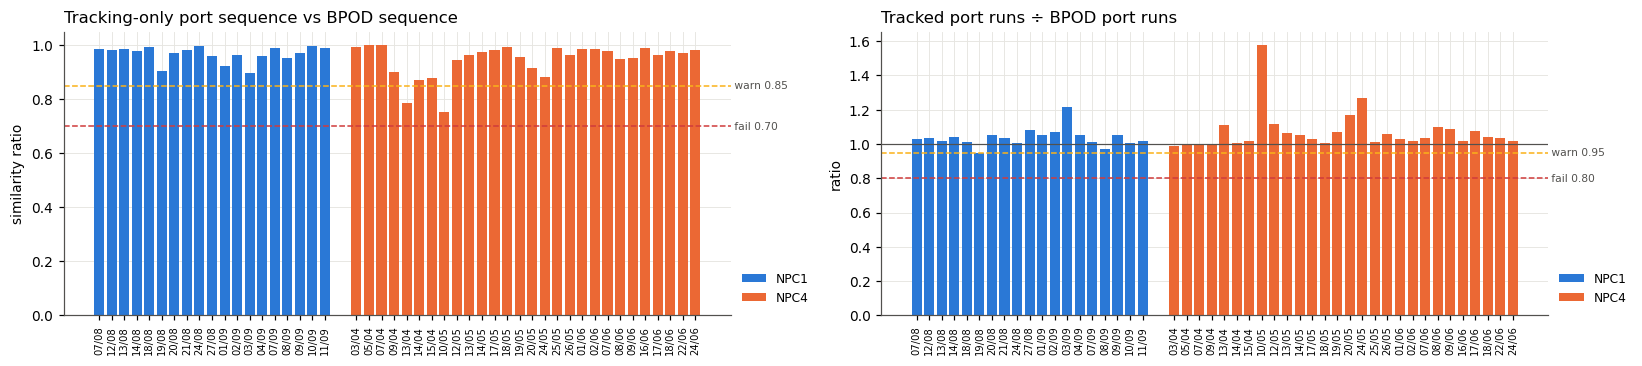

status,no_arrival_tracked %,ok %,prev_run_not_from_port %
subject,,,
NPC1,1.1,96.8,2.1
NPC4,2.5,92.4,5.1


In [20]:
qc['run_ratio'] = qc['n_tracked_port_runs'] / qc['n_bpod_port_runs']
fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
session_bars(axes[0], 'seq_agreement', 'Tracking-only port sequence vs BPOD sequence', 'similarity ratio',
             thresholds=(0.7, 0.85), fmt='{:.2f}')
axes[0].set_ylim(0, 1.05)
session_bars(axes[1], 'run_ratio', 'Tracked port runs ÷ BPOD port runs', 'ratio', thresholds=(0.8, 0.95), fmt='{:.2f}')
axes[1].axhline(1, color=INK2, lw=0.8)
fig.tight_layout(); plt.show()

# Why did BPOD port-to-port trials fail to get a travel time?
fail_mix = (trials[trials['status'].isin(['ok', 'no_arrival_tracked', 'prev_run_not_from_port'])]
            .groupby(['subject', 'status']).size().unstack(fill_value=0))
display((fail_mix.div(fail_mix.sum(axis=1), axis=0) * 100).round(1).add_suffix(' %'))

### 4.8 Graph legality and traversal smoothness

- **Illegal transitions:** consecutive `traversal_df` states that aren't
  adjacent in `G_aug`, counted within a trial. After the traversal fixer this
  should be close to 0.
- **Inferred rows:** steps the fixer filled in rather than observed. A high
  fraction means the raw tracking skipped a lot.
- **1-frame nodes / flicker:** a node held for a single frame, and X→Y→X
  patterns whose middle state lasts ≤ 2 frames. Both point to jitter at region
  boundaries.

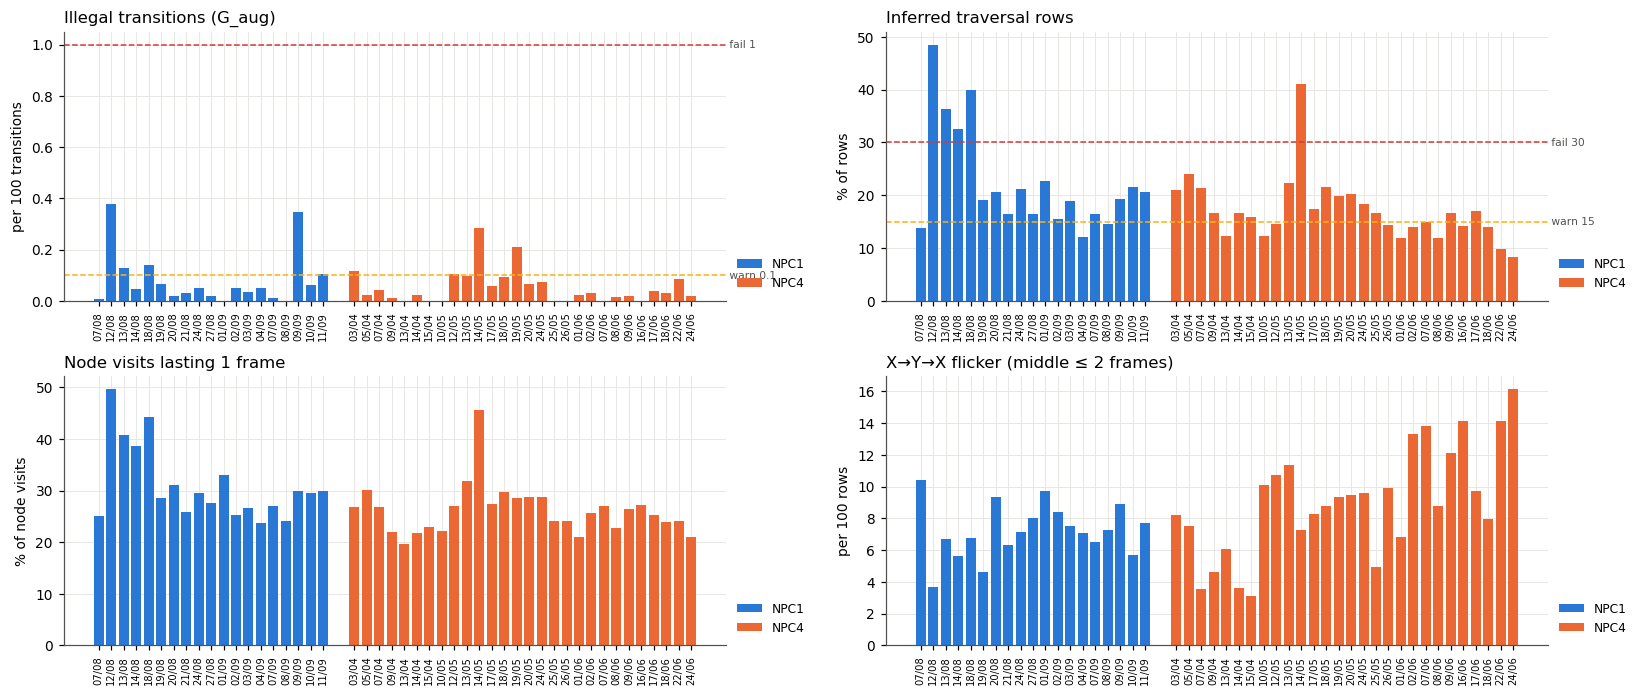

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(15, 6.4))
session_bars(axes[0, 0], 'illegal_per_100_transitions', 'Illegal transitions (G_aug)', 'per 100 transitions',
             thresholds=(1, 0.1), fmt='{:g}')
session_bars(axes[0, 1], 'pct_rows_inferred', 'Inferred traversal rows', '% of rows',
             thresholds=(30, 15))
session_bars(axes[1, 0], 'pct_1frame_nodes', 'Node visits lasting 1 frame', '% of node visits',
             thresholds=None)
session_bars(axes[1, 1], 'flicker_per_100_rows', 'X→Y→X flicker (middle ≤ 2 frames)', 'per 100 rows',
             thresholds=None)
fig.tight_layout(); plt.show()

### 4.9 Raw DLC quality

DLC likelihood isn't calibrated across models: NPC1's model sits near 0.88 in every
session, so the absolute % below 0.9 isn't comparable between subjects. The scorecard
rates each session against its own subject's median instead, which picks out
sessions that were probably tracked with a different model.

The panels show the headstage likelihood, and *teleports*: jumps larger than `TELEPORT_PX`
pixels between consecutive frames where both frames are confident. A confident
teleport is the most damaging error type, because the location step trusts it.

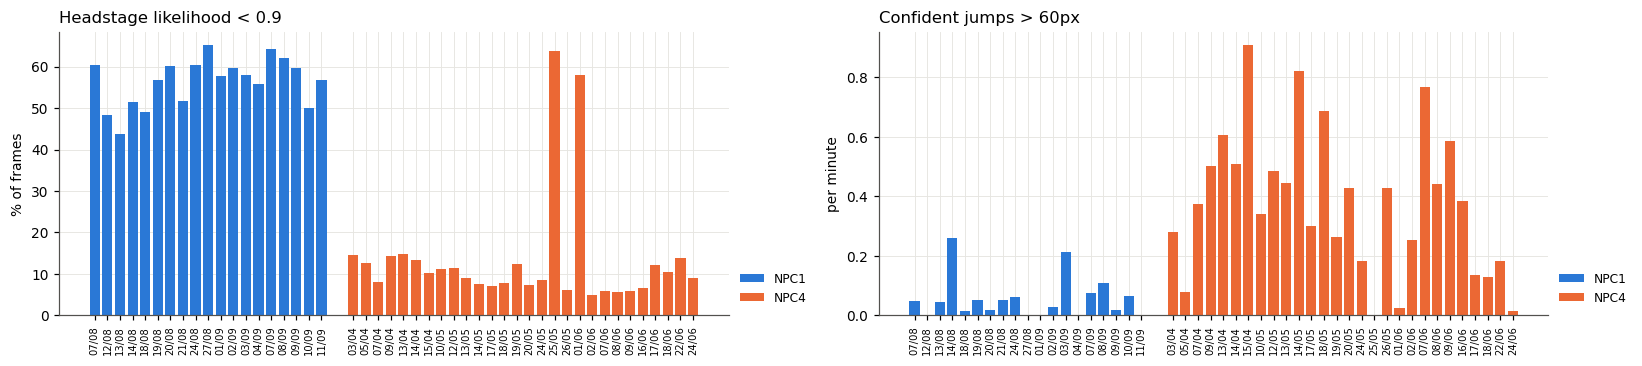

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
session_bars(axes[0], 'pct_low_likelihood', f'Headstage likelihood < {LOW_LIKELIHOOD}', '% of frames')
session_bars(axes[1], 'teleports_per_min', f'Confident jumps > {TELEPORT_PX}px', 'per minute',
             thresholds=None, fmt='{:.1f}')
fig.tight_layout(); plt.show()

### 4.10 Do the QC metrics explain each other?

Spearman correlations between the session-level metrics. For example, if
`on_port_pct` tracks `pct_low_likelihood`, the alignment check is really
measuring DLC quality. Strong pairs show which upstream stage to fix first.

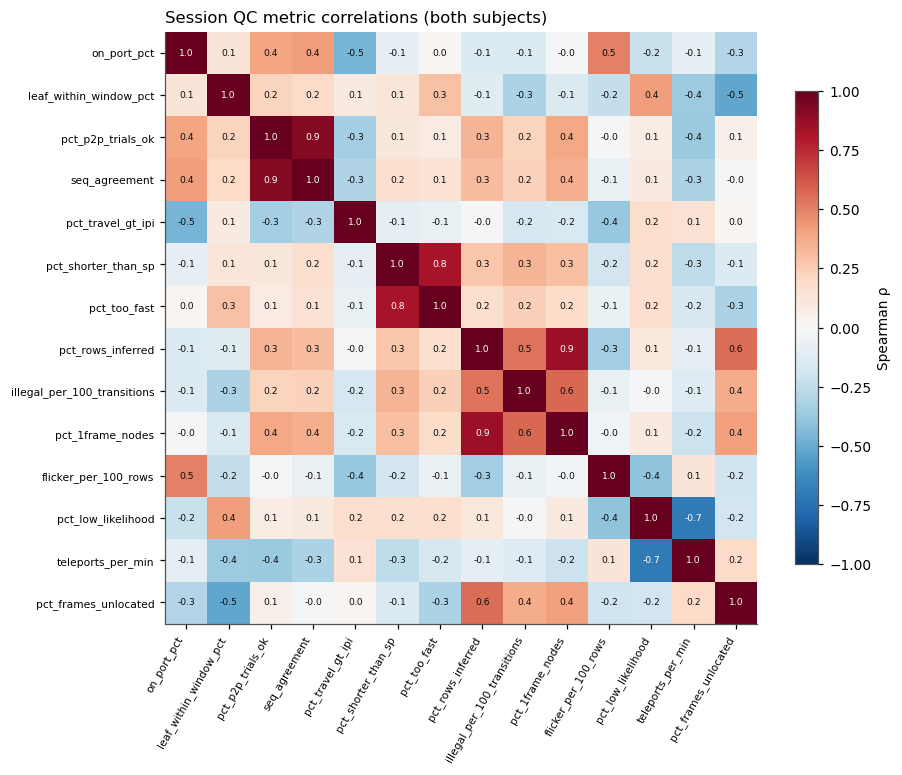

In [23]:
metric_cols = ['on_port_pct', 'leaf_within_window_pct', 'pct_p2p_trials_ok', 'seq_agreement', 'pct_travel_gt_ipi',
               'pct_shorter_than_sp', 'pct_too_fast', 'pct_rows_inferred', 'illegal_per_100_transitions',
               'pct_1frame_nodes', 'flicker_per_100_rows', 'pct_low_likelihood', 'teleports_per_min',
               'pct_frames_unlocated']
corr = qc[metric_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(metric_cols))); ax.set_xticklabels(metric_cols, rotation=60, ha='right', fontsize=7)
ax.set_yticks(range(len(metric_cols))); ax.set_yticklabels(metric_cols, fontsize=7)
for i in range(len(metric_cols)):
    for j in range(len(metric_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=6, color='white' if abs(v) > 0.6 else INK)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman ρ')
ax.set_title('Session QC metric correlations (both subjects)', loc='left')
fig.tight_layout(); plt.show()

## 5. Path length vs travel time

If the graph path is a faithful record of where the animal went, then a longer
tracked path should take proportionally longer. Each panel tests one part of that:

- **5.1** Travel time grows with the number of tracked hops.
- **5.2** Seconds per *tracked* hop are about the same for direct and indirect
  trials. If indirect paths were padded with hops the animal never walked, those
  hops would cost no time, and indirect trials would show **fewer** seconds per hop.
- **5.3** Each extra hop beyond the shortest path costs extra time, at roughly
  the direct-trial pace.
- **5.4** The pixel distance the headstage actually covered matches the graph
  path length. This is a check on the graph that doesn't depend on the graph.

`tracked_hops` counts every hop along the path, including repeats, and
`endpoint_sp_hops` is the shortest path between the same two nodes.

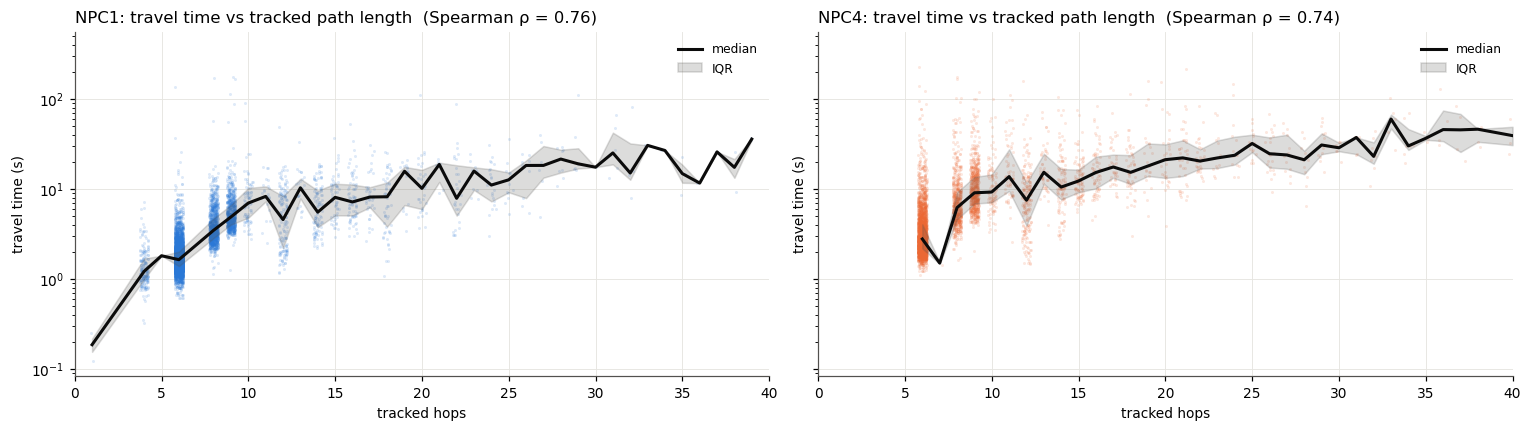

In [24]:
p2p['extra_hops'] = p2p['tracked_hops'] - p2p['endpoint_sp_hops']
p2p['is_indirect'] = p2p['extra_hops'] > 0
p2p['sec_per_tracked_hop'] = p2p['travel_s'] / p2p['tracked_hops']
p2p['px_len_ratio'] = p2p['px_path_hops'] / p2p['tracked_hops']      # pixel path ÷ graph path, in hop units
p2p['px_len_vs_sp'] = p2p['px_path_hops'] / p2p['endpoint_sp_hops']   # pixel path ÷ shortest path

fig, axes = plt.subplots(1, len(SUBJECTS), figsize=(7 * len(SUBJECTS), 4), squeeze=False, sharey=True)
for ax, subj in zip(axes[0], SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    ax.scatter(d['tracked_hops'] + np.random.uniform(-0.25, 0.25, len(d)), d['travel_s'], s=4, alpha=0.15,
               color=SUBJECT_COLOR[subj], linewidths=0)
    g = d[d['tracked_hops'] <= 40].groupby('tracked_hops')['travel_s']
    ax.plot(g.median().index, g.median(), color=INK, lw=2, label='median')
    ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75), color=INK2, alpha=0.2, label='IQR')
    rho = d[['tracked_hops', 'travel_s']].corr(method='spearman').iloc[0, 1]
    ax.set_yscale('log'); ax.set_xlim(0, 40)
    ax.set_xlabel('tracked hops'); ax.set_ylabel('travel time (s)')
    ax.set_title(f'{subj}: travel time vs tracked path length  (Spearman ρ = {rho:.2f})', loc='left')
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

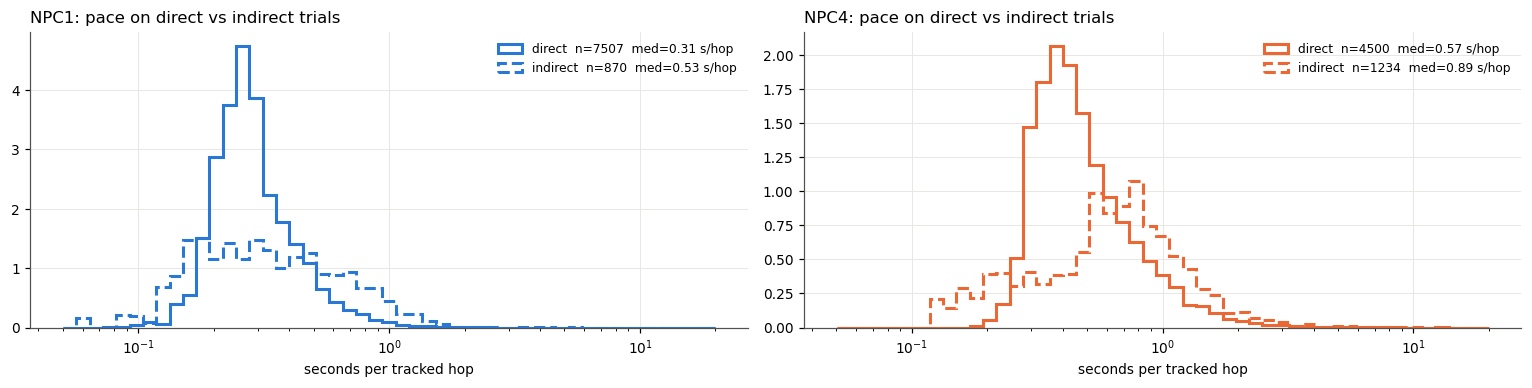

count    25%    50%    75%
subject is_indirect                             
NPC1    False        7507.0  0.246  0.308  0.438
        True          870.0  0.311  0.525  0.814
NPC4    False        4500.0  0.400  0.566  0.908
        True         1234.0  0.631  0.894  1.349

In [25]:
fig, axes = plt.subplots(1, len(SUBJECTS), figsize=(7 * len(SUBJECTS), 3.6), squeeze=False, sharex=True)
bins = np.logspace(-1.3, 1.3, 50)
for ax, subj in zip(axes[0], SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    for ind, ls, lab in [(False, '-', 'direct'), (True, '--', 'indirect')]:
        v = d.loc[d['is_indirect'] == ind, 'sec_per_tracked_hop']
        ax.hist(v, bins=bins, histtype='step', lw=2, ls=ls, color=SUBJECT_COLOR[subj], density=True,
                label=f'{lab}  n={len(v)}  med={v.median():.2f} s/hop')
    ax.set_xscale('log'); ax.set_xlabel('seconds per tracked hop')
    ax.set_title(f'{subj}: pace on direct vs indirect trials', loc='left'); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

pace = p2p.groupby(['subject', 'is_indirect'])['sec_per_tracked_hop'].describe(percentiles=[.25, .5, .75])
display(pace[['count', '25%', '50%', '75%']].round(3))

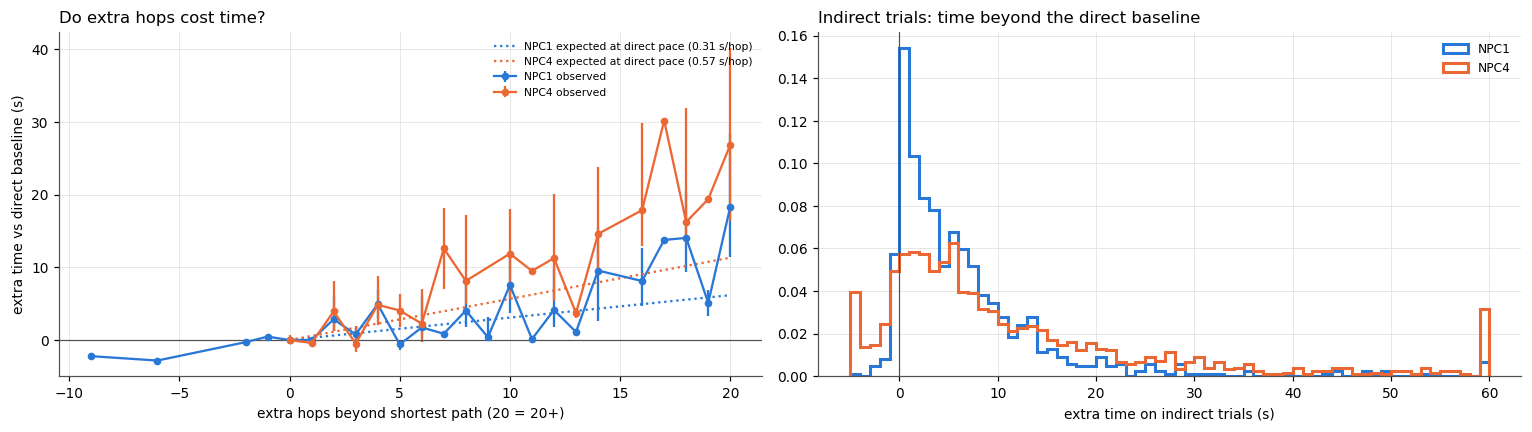

Indirect trials that took no longer than the direct baseline (≤ 0 s extra):
subject
NPC1     7.8 %
NPC4    14.2 %
Name: extra_time_s, dtype: str


In [26]:
# Extra time paid for each extra hop, against a direct-trial baseline for the same
# session and port pair (falling back to the subject-wide pair baseline).
direct = p2p[~p2p['is_indirect']]
base_sess = direct.groupby(['subject', 'session', 'pair'])['travel_s'].median().rename('base_sess')
base_subj = direct.groupby(['subject', 'pair'])['travel_s'].median().rename('base_subj')
p2p = p2p.join(base_sess, on=['subject', 'session', 'pair']).join(base_subj, on=['subject', 'pair'])
p2p['direct_baseline_s'] = p2p['base_sess'].fillna(p2p['base_subj'])
p2p['extra_time_s'] = p2p['travel_s'] - p2p['direct_baseline_s']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for subj in SUBJECTS:
    d = p2p[p2p['subject'] == subj].dropna(subset=['extra_time_s'])
    d = d.assign(xb=d['extra_hops'].clip(upper=20))
    g = d.groupby('xb')['extra_time_s']
    pace_direct = d.loc[~d['is_indirect'], 'sec_per_tracked_hop'].median()
    axes[0].errorbar(g.median().index, g.median(), yerr=[g.median() - g.quantile(0.25), g.quantile(0.75) - g.median()],
                     fmt='o-', ms=4, lw=1.5, capsize=0, color=SUBJECT_COLOR[subj], label=f'{subj} observed')
    xs = np.arange(0, 21)
    axes[0].plot(xs, xs * pace_direct, ':', color=SUBJECT_COLOR[subj], lw=1.5,
                 label=f'{subj} expected at direct pace ({pace_direct:.2f} s/hop)')
    axes[1].hist(d.loc[d['is_indirect'], 'extra_time_s'].clip(-5, 60), bins=np.linspace(-5, 60, 66),
                 histtype='step', lw=2, color=SUBJECT_COLOR[subj], density=True, label=subj)
axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set_xlabel('extra hops beyond shortest path (20 = 20+)'); axes[0].set_ylabel('extra time vs direct baseline (s)')
axes[0].set_title('Do extra hops cost time?', loc='left'); axes[0].legend(frameon=False, fontsize=7)
axes[1].axvline(0, color=INK2, lw=0.8)
axes[1].set_xlabel('extra time on indirect trials (s)'); axes[1].set_title('Indirect trials: time beyond the direct baseline', loc='left')
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print('Indirect trials that took no longer than the direct baseline (≤ 0 s extra):')
print((p2p[p2p['is_indirect']].groupby('subject')['extra_time_s'].apply(lambda x: (x <= 0).mean() * 100)).round(1).astype(str) + ' %')

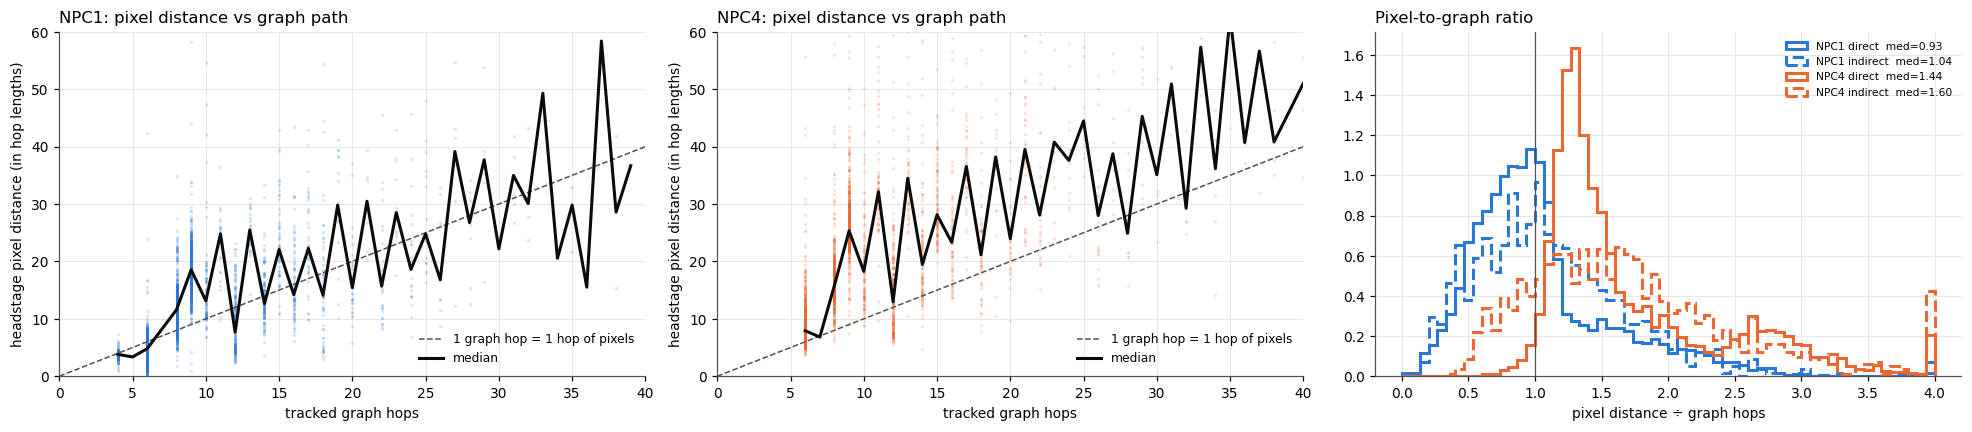

In [27]:
fig, axes = plt.subplots(1, len(SUBJECTS) + 1, figsize=(6 * (len(SUBJECTS) + 1), 4), squeeze=False)
for ax, subj in zip(axes[0], SUBJECTS):
    d = p2p[p2p['subject'] == subj]
    ax.scatter(d['tracked_hops'], d['px_path_hops'], s=4, alpha=0.2, color=SUBJECT_COLOR[subj], linewidths=0)
    ax.plot([0, 40], [0, 40], '--', color=INK2, lw=1, label='1 graph hop = 1 hop of pixels')
    g = d[d['tracked_hops'] <= 40].groupby('tracked_hops')['px_path_hops'].median()
    ax.plot(g.index, g.values, color=INK, lw=2, label='median')
    ax.set_xlim(0, 40); ax.set_ylim(0, 60)
    ax.set_xlabel('tracked graph hops'); ax.set_ylabel('headstage pixel distance (in hop lengths)')
    ax.set_title(f'{subj}: pixel distance vs graph path', loc='left'); ax.legend(frameon=False, fontsize=8)
ax = axes[0, -1]
for subj in SUBJECTS:
    for ind, ls in [(False, '-'), (True, '--')]:
        v = p2p.loc[(p2p['subject'] == subj) & (p2p['is_indirect'] == ind), 'px_len_ratio'].clip(upper=4)
        ax.hist(v, bins=np.linspace(0, 4, 61), histtype='step', lw=2, ls=ls, color=SUBJECT_COLOR[subj], density=True,
                label=f"{subj} {'indirect' if ind else 'direct'}  med={v.median():.2f}")
ax.axvline(1, color=INK2, lw=0.8)
ax.set_xlabel('pixel distance ÷ graph hops'); ax.set_title('Pixel-to-graph ratio', loc='left')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()

## 6. Are indirect paths real?

An indirect trial (tracked hops > shortest-path hops) is either a real
excursion, or something produced by tracking noise or by the correction step
(inferred rows). It comes in two shapes:

- **Detour:** the path visits nodes off the shortest path.
- **Reversal:** the path stays on the shortest path but goes back and forth
  along it.

Each indirect trial is tested against independent lines of evidence:

| Evidence | Detour | Reversal |
|---|---|---|
| **Graph**: the extra part was *observed*, not inferred | ≥ `MIN_DETOUR_FRAMES` non-inferred frames off the path | < 50 % of rows in the travel window inferred |
| **Pixels (headstage)**: the animal physically left the shortest corridor / walked further | sustained distance from the shortest-path corridor above the noise floor | pixel distance ÷ shortest-path hops above the noise floor |
| **Pixels (midbody)**: a second body part, with its own DLC point, agrees | as above, for midbody | — |

The **noise floor** comes from the data itself: the 95th percentile of the
same metric on *direct* trials of the same subject. On those trials the animal
stayed on the shortest path by definition, so any distance they show is tracking
noise plus corridor width.

The categories are:
- **confirmed:** graph and headstage-pixel evidence both agree.
- **graph only:** observed off-path nodes, but the pixels stay in the corridor.
  These are probably region-boundary jitter.
- **pixel only:** the animal moved off-path, but the graph inferred the detour.
- **unsupported:** neither line of evidence. These are probably artefacts.

**Created by correction** marks detours whose off-path rows are *all* inferred.

A typical *graph only* detour is several hops deep in the graph, yet the pixels
never leave the corridor and it costs almost no extra time. That is the signature
of a mapping overlap: a corridor across a wall that is close in the image but far
in the graph. A few observed frames land in the wrong region, and the correction
step then infers the hops needed to get there and back. The table below shows
the median depth, extra time and pixel distance for each category, so you can
check this for yourself.

In [28]:
ind = p2p['is_indirect']
p2p['indirect_type'] = np.select([~ind, p2p['n_offpath_nodes'] > 0], ['direct', 'detour'], 'reversal')
noise = p2p[~ind].groupby('subject')[['px_offpath_hops', 'mid_offpath_hops', 'px_len_vs_sp']].quantile(0.95)
print('Noise floor (95th pct on direct trials), in hop lengths:')
display(noise.round(2))

nz = noise.reindex(p2p['subject']).set_axis(p2p.index)
det, rev = p2p['indirect_type'] == 'detour', p2p['indirect_type'] == 'reversal'
p2p['ev_graph'] = np.where(det, p2p['offpath_observed_frames'] >= MIN_DETOUR_FRAMES,
                           np.where(rev, p2p['win_inferred_frac'] < 0.5, np.nan))
p2p['ev_pixel'] = np.where(det, p2p['px_offpath_hops'] > nz['px_offpath_hops'],
                           np.where(rev, p2p['px_len_vs_sp'] > nz['px_len_vs_sp'], np.nan))
p2p['ev_midbody'] = np.where(det, p2p['mid_offpath_hops'] > nz['mid_offpath_hops'], np.nan)
p2p['made_by_correction'] = det & (p2p['offpath_observed_frames'] == 0)
p2p['indirect_support'] = np.select(
    [~ind, (p2p['ev_graph'] == 1) & (p2p['ev_pixel'] == 1), p2p['ev_graph'] == 1, p2p['ev_pixel'] == 1],
    ['direct', 'confirmed', 'graph only', 'pixel only'], 'unsupported')

SUPPORT_ORDER = ['confirmed', 'pixel only', 'graph only', 'unsupported']
SUPPORT_COLOR = {'confirmed': '#2a78d6', 'pixel only': '#86b6ef', 'graph only': '#eda100', 'unsupported': '#d03b3b'}

tab = (p2p[ind].groupby(['subject', 'indirect_type'])['indirect_support'].value_counts(normalize=True)
       .mul(100).unstack(fill_value=0).reindex(columns=SUPPORT_ORDER, fill_value=0).round(1))
tab['n'] = p2p[ind].groupby(['subject', 'indirect_type']).size()
tab['% made by correction'] = (p2p[ind].groupby(['subject', 'indirect_type'])['made_by_correction'].mean() * 100).round(1)
tab['% midbody agrees'] = (p2p[det].groupby(['subject', 'indirect_type'])['ev_midbody'].mean() * 100).round(1)
print('\nIndirect trials by evidence category (% of row):')
display(tab)
print('\nMedian profile of each category (detours):')
display(p2p[det].groupby(['subject', 'indirect_support'])[
    ['detour_depth', 'extra_hops', 'offpath_observed_frames', 'px_offpath_hops', 'mid_offpath_hops', 'extra_time_s']
].median().round(2))
print('\nShare of timed trials that are indirect:')
print((p2p.groupby('subject')['is_indirect'].mean() * 100).round(1).astype(str) + ' %')

Noise floor (95th pct on direct trials), in hop lengths:


,px_offpath_hops,mid_offpath_hops,px_len_vs_sp
subject,,,
NPC1,0.80,0.82,2.18
NPC4,0.65,0.65,3.11



Indirect trials by evidence category (% of row):


indirect_support       confirmed  pixel only  graph only  unsupported     n  \
subject indirect_type                                                         
NPC1    detour              64.1         1.0        22.1         12.7   863   
        reversal            42.9         0.0        57.1          0.0     7   
NPC4    detour              82.9         0.5         8.8          7.8  1211   
        reversal            56.5         0.0        39.1          4.3    23   

indirect_support       % made by correction  % midbody agrees  
subject indirect_type                                          
NPC1    detour                          4.1              62.1  
        reversal                        0.0               NaN  
NPC4    detour                          3.0              76.5  
        reversal                        0.0               NaN


Median profile of each category (detours):


detour_depth  extra_hops  offpath_observed_frames  \
subject indirect_support                                                      
NPC1    confirmed                  3.0         8.0                    184.0   
        graph only                 3.0         6.0                     15.0   
        pixel only                 3.0         6.0                      1.0   
        unsupported                3.0         6.0                      1.0   
NPC4    confirmed                  3.0         6.0                    232.5   
        graph only                 3.0         6.0                     16.0   
        pixel only                 3.0         6.0                      1.0   
        unsupported                3.0         6.0                      1.0   

                          px_offpath_hops  mid_offpath_hops  extra_time_s  
subject indirect_support                                                   
NPC1    confirmed                    1.93              1.75          7.06  
        graph only                   0.31              0.43          1.17  
        pixel only                   1.19              1.21          1.60  
        unsupported                  0.30              0.43          0.24  
NPC4    confirmed                    1.67              1.44          8.20  
        graph only                   0.38              0.38          1.15  
        pixel only                   0.86              0.55          2.07  
        unsupported                  0.29              0.41         -0.12


Share of timed trials that are indirect:
subject
NPC1    10.4 %
NPC4    21.5 %
Name: is_indirect, dtype: str


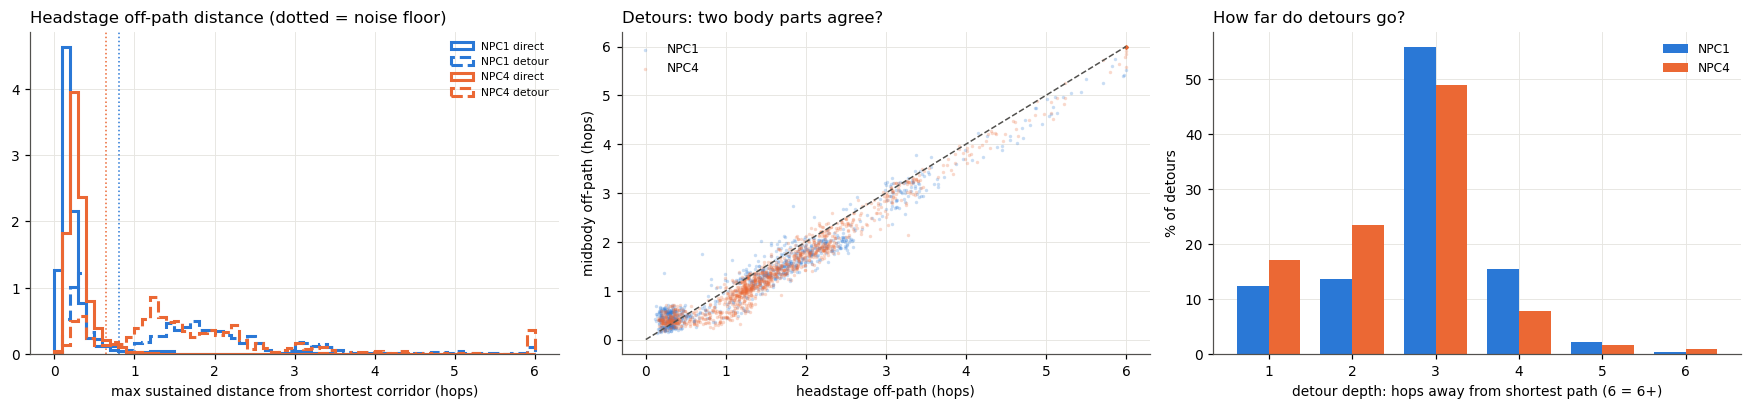

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for subj in SUBJECTS:
    for t, ls in [('direct', '-'), ('detour', '--')]:
        v = p2p.loc[(p2p['subject'] == subj) & (p2p['indirect_type'] == t), 'px_offpath_hops'].clip(upper=6)
        axes[0].hist(v, bins=np.linspace(0, 6, 61), histtype='step', lw=2, ls=ls, density=True,
                     color=SUBJECT_COLOR[subj], label=f'{subj} {t}')
    axes[0].axvline(noise.loc[subj, 'px_offpath_hops'], color=SUBJECT_COLOR[subj], lw=1, ls=':')
axes[0].set_xlabel('max sustained distance from shortest corridor (hops)')
axes[0].set_title('Headstage off-path distance (dotted = noise floor)', loc='left'); axes[0].legend(frameon=False, fontsize=7)

for subj in SUBJECTS:
    d = p2p[(p2p['subject'] == subj) & det]
    axes[1].scatter(d['px_offpath_hops'].clip(upper=6), d['mid_offpath_hops'].clip(upper=6), s=5, alpha=0.25,
                    color=SUBJECT_COLOR[subj], linewidths=0, label=subj)
axes[1].plot([0, 6], [0, 6], '--', color=INK2, lw=1)
axes[1].set_xlabel('headstage off-path (hops)'); axes[1].set_ylabel('midbody off-path (hops)')
axes[1].set_title('Detours: two body parts agree?', loc='left'); axes[1].legend(frameon=False, fontsize=8)

dd = p2p[det]
depth_tab = dd.groupby(['subject', dd['detour_depth'].clip(upper=6)]).size().unstack(0, fill_value=0)
depth_tab = depth_tab / depth_tab.sum() * 100
w = 0.38
for k, subj in enumerate(SUBJECTS):
    if subj in depth_tab:
        axes[2].bar(depth_tab.index + (k - 0.5) * w, depth_tab[subj], width=w, color=SUBJECT_COLOR[subj], label=subj)
axes[2].set_xlabel('detour depth: hops away from shortest path (6 = 6+)'); axes[2].set_ylabel('% of detours')
axes[2].set_title('How far do detours go?', loc='left'); axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

### 6.0 Where do the artefact detours happen?

If unsupported detours come from mapping overlap, they should keep landing on
the **same few nodes**. Real detours should spread across the maze. The table
ranks the off-path nodes of *graph only* + *unsupported* detours, alongside how
often the same node appears in *confirmed* detours. A node that shows up almost
only in artefacts is a mapping region worth redrawing.

In [30]:
def offpath_nodes(row):
    path = row['path_nodes'].split()
    sp = set(nx.shortest_path(G, path[0], path[-1]))
    return sorted({n for n in path if n not in sp})


dd = p2p[det].copy()
dd['off_nodes'] = dd.apply(offpath_nodes, axis=1)
dd['artefact'] = dd['indirect_support'].isin(['graph only', 'unsupported'])
ex = dd.explode('off_nodes').dropna(subset=['off_nodes'])
hot = (ex.groupby(['subject', 'off_nodes'])
         .agg(artefact_trials=('artefact', 'sum'), confirmed_trials=('indirect_support', lambda x: (x == 'confirmed').sum()),
              sessions=('session', 'nunique'))
         .assign(artefact_share=lambda t: (t['artefact_trials'] / (t['artefact_trials'] + t['confirmed_trials'])).round(2)))
for subj in SUBJECTS:
    print(f'{subj}: off-path nodes most involved in artefact detours')
    display(hot.loc[subj].sort_values('artefact_trials', ascending=False).head(10))
hot.to_csv(QC_DIR / 'artefact_detour_nodes.csv')

NPC1: off-path nodes most involved in artefact detours


,artefact_trials,confirmed_trials,sessions,artefact_share
off_nodes,,,,
R30,107,45,15,0.70
R40,106,19,9,0.85
R415,106,33,10,0.76
R37,105,76,17,0.58
R50,105,14,7,0.88
R531,83,21,9,0.80
R530,70,25,9,0.74
L516,42,7,4,0.86
L48,42,15,9,0.74


NPC4: off-path nodes most involved in artefact detours


,artefact_trials,confirmed_trials,sessions,artefact_share
off_nodes,,,,
L33,100,223,26,0.31
L515,100,112,14,0.47
L47,100,126,18,0.44
R47,71,54,21,0.57
R33,71,96,25,0.43
R515,71,42,16,0.63
R30,21,72,25,0.23
R50,21,21,11,0.50
R40,21,38,19,0.36


### 6.1 Evidence per session

The share of each session's indirect trials in each evidence category. A session
where *unsupported* or *graph only* dominates is one whose indirect-path counts
shouldn't be trusted, and it is penalised in the scorecard via
`pct_indirect_unsupported`.

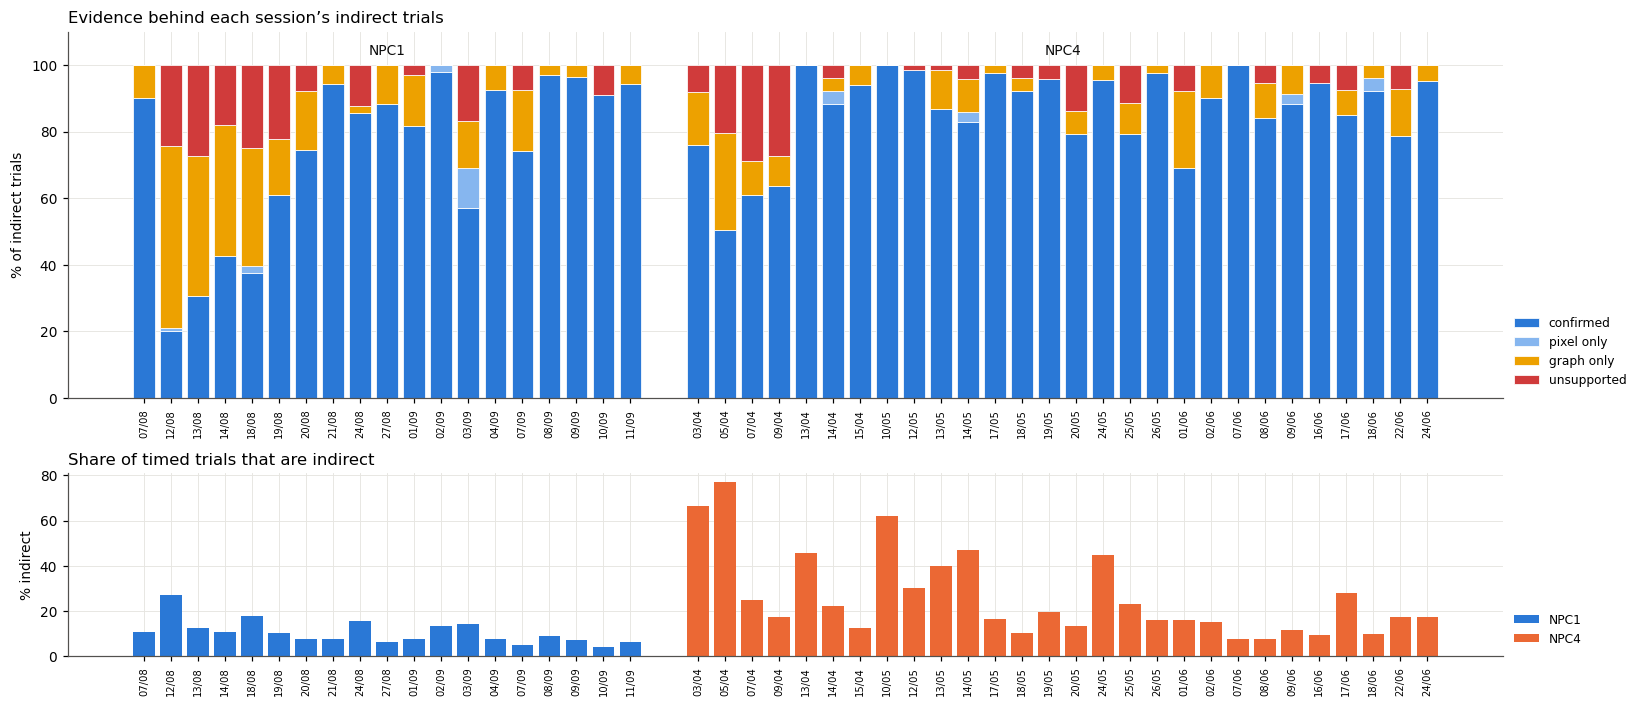

In [31]:
cat = (p2p[ind].groupby(['subject', 'session'])['indirect_support'].value_counts(normalize=True).mul(100)
       .unstack(fill_value=0).reindex(columns=SUPPORT_ORDER, fill_value=0))
qc = qc.drop(columns=[c for c in ['pct_indirect', 'pct_indirect_unsupported', 'pct_indirect_confirmed',
                                  'sec_per_hop_ratio_ind_dir'] if c in qc.columns])
extra = pd.DataFrame({
    'pct_indirect': p2p.groupby(['subject', 'session'])['is_indirect'].mean() * 100,
    'pct_indirect_unsupported': cat['unsupported'] + cat['graph only'],
    'pct_indirect_confirmed': cat['confirmed'],
    'sec_per_hop_ratio_ind_dir': (p2p[ind].groupby(['subject', 'session'])['sec_per_tracked_hop'].median()
                                  / p2p[~ind].groupby(['subject', 'session'])['sec_per_tracked_hop'].median()),
}).reset_index()
qc = qc.merge(extra, on=['subject', 'session'], how='left')

fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), gridspec_kw={'height_ratios': [2, 1]})
x0 = 0; ticks = []; labels = []
for subj in SUBJECTS:
    sess = qc.loc[qc['subject'] == subj, ['session', 'label']]
    xs = np.arange(x0, x0 + len(sess))
    bottom = np.zeros(len(sess))
    for c in SUPPORT_ORDER:
        v = cat[c].reindex(pd.MultiIndex.from_product([[subj], sess['session']])).fillna(0).to_numpy()
        axes[0].bar(xs, v, bottom=bottom, color=SUPPORT_COLOR[c], width=0.8, edgecolor='white', linewidth=0.5,
                    label=c if subj == SUBJECTS[0] else None)
        bottom += v
    axes[1].bar(xs, qc.loc[qc['subject'] == subj, 'pct_indirect'], color=SUBJECT_COLOR[subj], width=0.8, label=subj)
    axes[0].text(xs.mean(), 103, subj, ha='center', fontsize=9, color=INK)
    ticks += list(xs); labels += list(sess['label']); x0 += len(sess) + 1.5
axes[0].set_ylim(0, 110); axes[0].set_ylabel('% of indirect trials')
axes[0].set_title('Evidence behind each session’s indirect trials', loc='left')
axes[0].legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(1.0, 0.0))
axes[1].set_ylabel('% indirect'); axes[1].set_title('Share of timed trials that are indirect', loc='left')
axes[1].legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(1.0, 0.0))
for ax in axes:
    ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=90, fontsize=6.5)
fig.tight_layout(); plt.show()

### 6.2 Look at them: trajectory gallery

The raw headstage pixel trajectory for randomly sampled indirect trials, drawn
over the maze's node and corridor centroids:
- **grey dots:** the maze nodes and corridors.
- **thick grey line:** the shortest path.
- **colored trajectory:** the headstage, light to dark over time.
- **dashed black line:** the tracked graph path.

A real detour shows the trajectory leaving the grey corridor. An artefact shows
the dashed path wandering while the trajectory stays on the corridor. Change
`GALLERY_SEED` to draw a new sample.

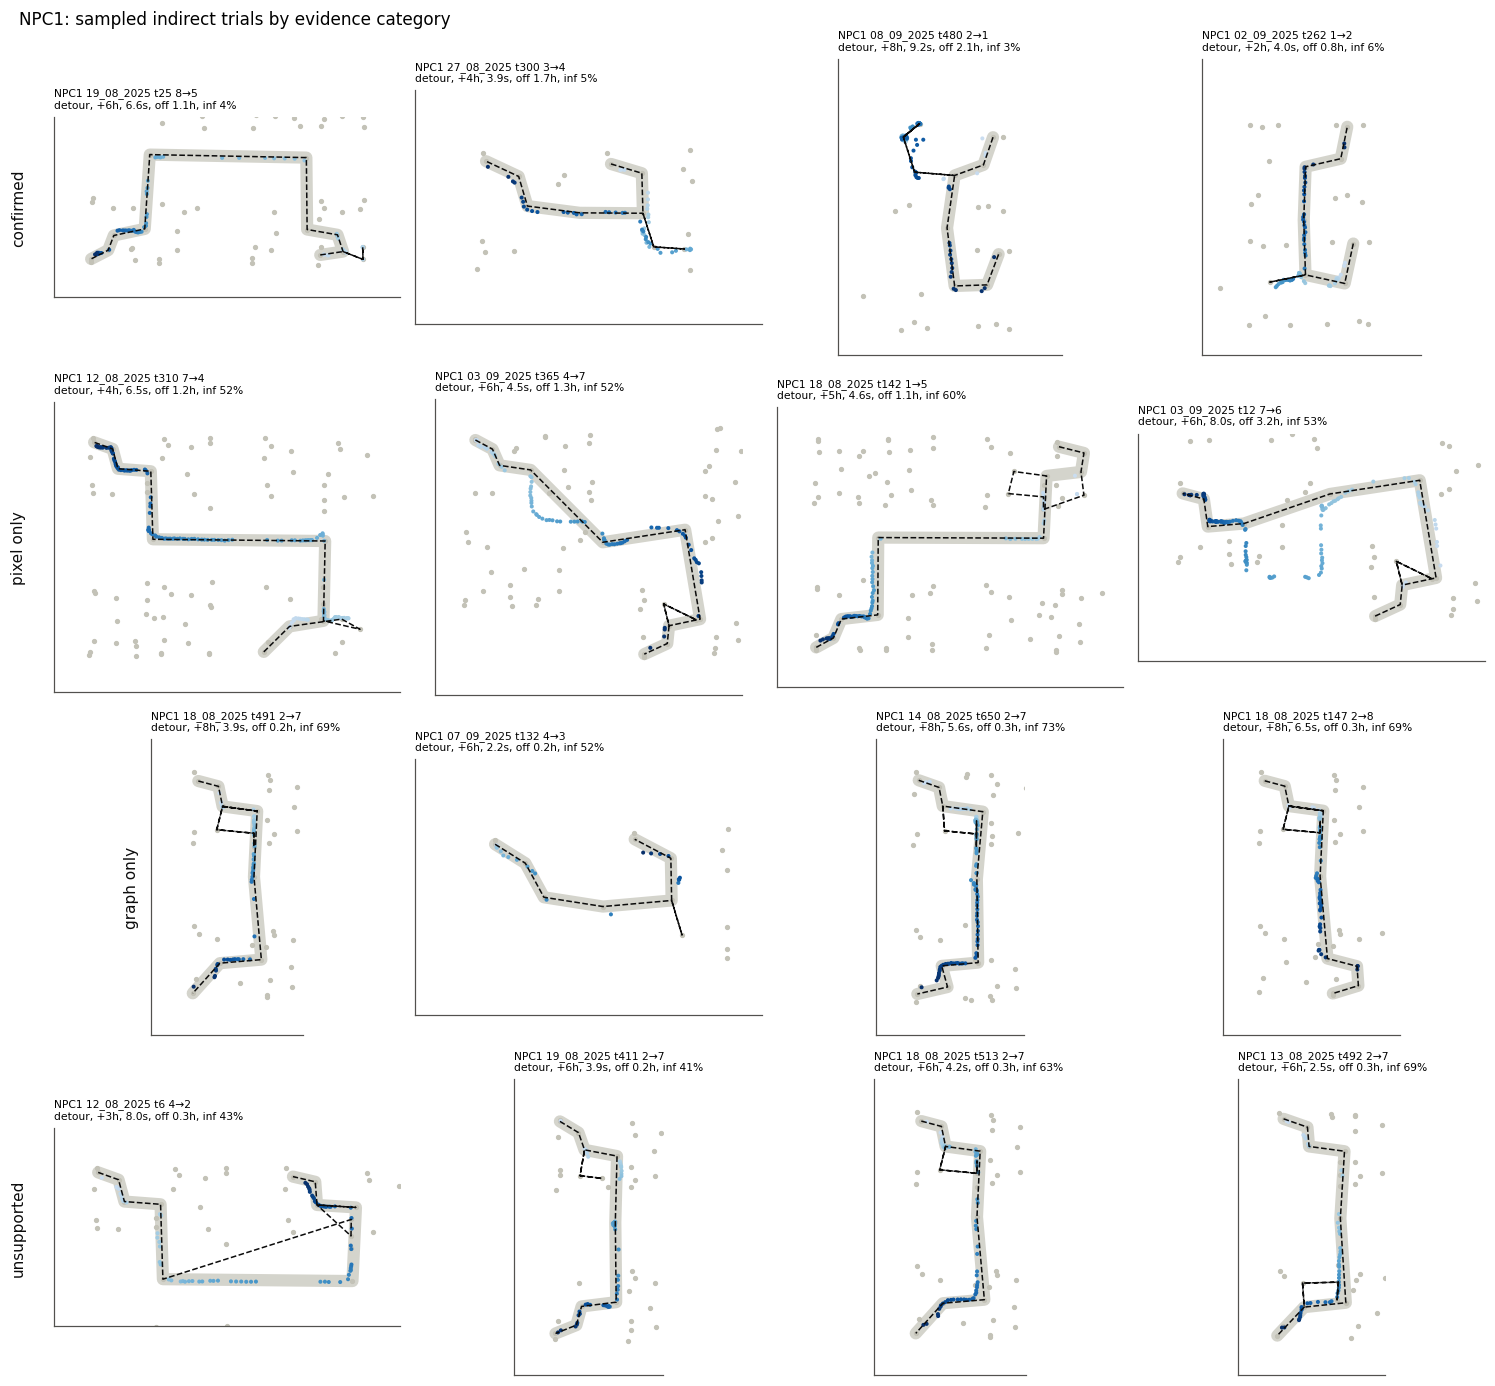

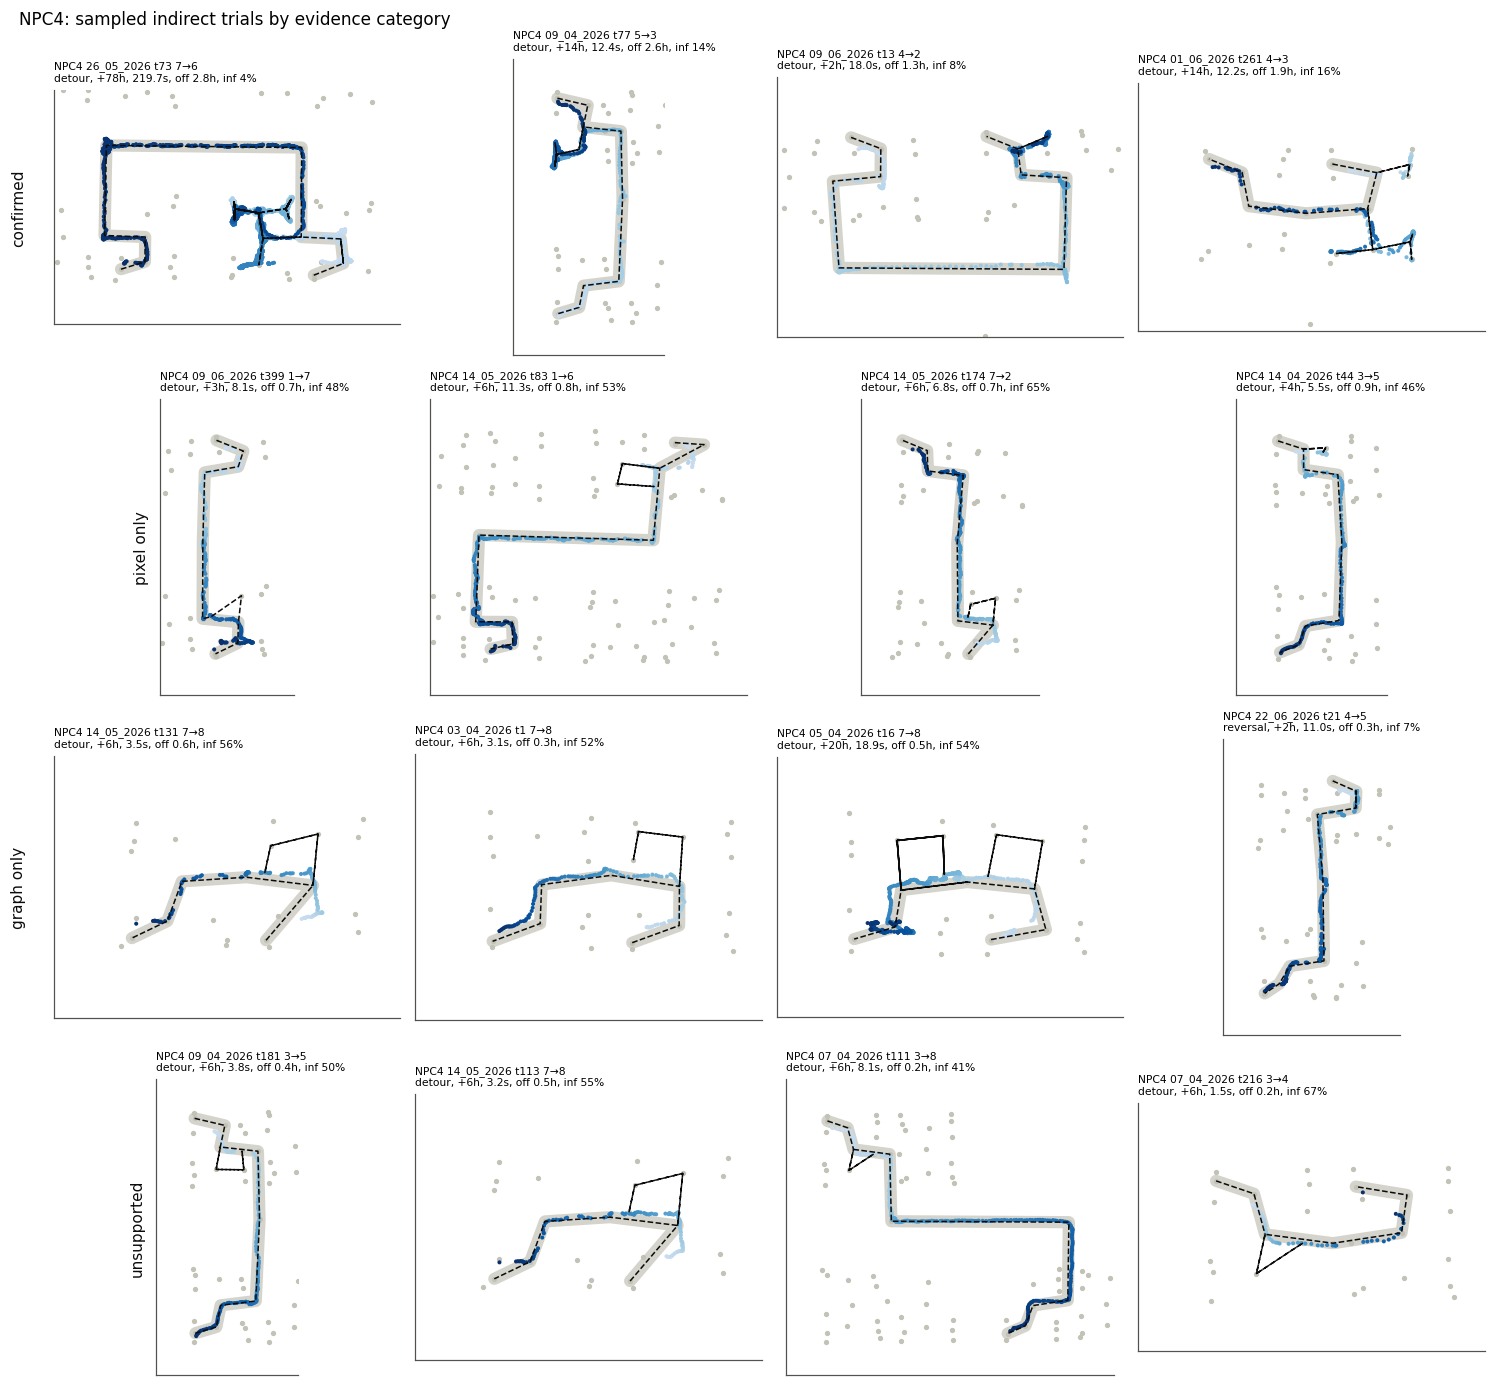

In [32]:
from functools import lru_cache

GALLERY_SEED, PER_CATEGORY = 0, 4


@lru_cache(maxsize=8)
def _session_pixels(subject, session):
    summ = _flatten_cols(pd.read_pickle(OUTPUTS / subject / session / 'summary_df.pkl'))
    summ = summ.sort_values('frame_idx_global').reset_index(drop=True)
    return summ, region_centroids(summ)


def plot_trial_trajectory(row, ax):
    summ, (cn, ce, hop) = _session_pixels(row['subject'], row['session'])
    allpts = np.array(list(cn.values()) + list(ce.values()))
    ax.scatter(allpts[:, 0], allpts[:, 1], s=6, color='#c3c2b7', zorder=1)
    path = row['path_nodes'].split()
    sp = nx.shortest_path(G, path[0], path[-1])
    spl = path_polyline(sp, cn, ce)
    ax.plot(spl[:, 0], spl[:, 1], color='#c3c2b7', lw=8, alpha=0.7, solid_capstyle='round', zorder=2)
    tpl = path_polyline(path, cn, ce)
    ax.plot(tpl[:, 0], tpl[:, 1], '--', color=INK, lw=1, zorder=4)
    fr = summ['frame_idx_global'].to_numpy()
    i0, i1 = np.searchsorted(fr, [row['depart_frame'], row['arrive_frame'] + 1])
    seg = summ.iloc[i0:i1]
    seg = seg[seg['headstage_likelihood'] >= LOW_LIKELIHOOD]
    ax.scatter(seg['headstage_x'], seg['headstage_y'], c=np.linspace(0, 1, len(seg)), cmap='Blues', vmin=-0.3,
               s=7, zorder=3, linewidths=0)
    pad = 2 * hop
    xs = np.r_[spl[:, 0], tpl[:, 0], seg['headstage_x']]; ys = np.r_[spl[:, 1], tpl[:, 1], seg['headstage_y']]
    ax.set_xlim(xs.min() - pad, xs.max() + pad); ax.set_ylim(ys.max() + pad, ys.min() - pad)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{row['subject']} {row['session']} t{row['trial_idx']} {row['pair']}\n"
                 f"{row['indirect_type']}, +{int(row['extra_hops'])}h, {row['travel_s']:.1f}s, "
                 f"off {row['px_offpath_hops']:.1f}h, inf {row['win_inferred_frac']:.0%}", fontsize=7, loc='left')


rng = np.random.default_rng(GALLERY_SEED)
for subj in SUBJECTS:
    fig, axes = plt.subplots(len(SUPPORT_ORDER), PER_CATEGORY, figsize=(3.4 * PER_CATEGORY, 3.2 * len(SUPPORT_ORDER)))
    for r_, c in enumerate(SUPPORT_ORDER):
        pool = p2p[(p2p['subject'] == subj) & (p2p['indirect_support'] == c)]
        pick = pool.iloc[rng.choice(len(pool), min(PER_CATEGORY, len(pool)), replace=False)] if len(pool) else pool
        for k in range(PER_CATEGORY):
            ax = axes[r_, k]
            if k < len(pick):
                plot_trial_trajectory(pick.iloc[k], ax)
            else:
                ax.set_visible(False)
        axes[r_, 0].text(-0.08, 0.5, c, transform=axes[r_, 0].transAxes, rotation=90, ha='right', va='center',
                         fontsize=10, color=INK)
    fig.suptitle(f'{subj}: sampled indirect trials by evidence category', x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    fig.savefig(QC_DIR / f'{subj}_indirect_gallery.png', dpi=130, bbox_inches='tight')
    plt.show()

### 6.3 Blind video review sheet

The automated categories still need ground truth. This cell writes a shuffled
sample of indirect trials (equal numbers per category, plus direct trials as
controls) **without** the category, and saves the answer key separately. Watch
each clip (for example with `extract_trial_video` in `session_pipeline.ipynb`, using
`depart_frame` / `arrive_frame`), mark `real_detour` yes/no, then run the next
cell to see how well each category predicts the human call.

In [33]:
REVIEW_PER_CATEGORY = 10
rng = np.random.default_rng(1)
picks = []
for subj in SUBJECTS:
    for c in SUPPORT_ORDER + ['direct']:
        pool = p2p[(p2p['subject'] == subj) & (p2p['indirect_support'] == c)]
        if len(pool):
            picks.append(pool.iloc[rng.choice(len(pool), min(REVIEW_PER_CATEGORY, len(pool)), replace=False)])
review = pd.concat(picks).sample(frac=1, random_state=2).reset_index(drop=True)
review['review_id'] = np.arange(len(review))
sheet_cols = ['review_id', 'subject', 'session', 'trial_idx', 'pair', 'depart_frame', 'arrive_frame', 'path_nodes']
review_path, key_path = QC_DIR / 'indirect_review_sheet.csv', QC_DIR / 'indirect_review_key.csv'
if review_path.exists():
    print(f'{review_path.name} already exists. Not overwriting it, so your annotations are safe.')
else:
    review[sheet_cols].assign(real_detour='').to_csv(review_path, index=False)
    review[['review_id', 'indirect_support', 'indirect_type']].to_csv(key_path, index=False)
    print(f'Wrote {len(review)} trials to {review_path}\nKey: {key_path}')

indirect_review_sheet.csv already exists. Not overwriting it, so your annotations are safe.


In [34]:
# After annotating: how well does each automated category match the human call?
sheet = pd.read_csv(review_path)
done = sheet[sheet['real_detour'].astype(str).str.lower().isin(['yes', 'no', 'y', 'n', '1', '0', 'true', 'false'])]
if done.empty:
    print('No annotations yet. Fill the real_detour column in', review_path.name)
else:
    done = done.merge(pd.read_csv(key_path), on='review_id')
    done['real'] = done['real_detour'].astype(str).str.lower().isin(['yes', 'y', '1', 'true'])
    display(done.groupby('indirect_support')['real'].agg(n='size', pct_real=lambda x: round(100 * x.mean(), 1)))

No annotations yet. Fill the real_detour column in indirect_review_sheet.csv


## 7. Is NPC4's graph tracking as reliable as NPC1's?

Session-level metrics compared between subjects (median and IQR across
sessions), with a Mann-Whitney U test treating sessions as the unit. Look at
the direction column, not just the p-value: some differences are camera or
behavioural, not reliability. For example, NPC4 being slower is behaviour, but
NPC4 having more unsupported detours is a tracking problem.

In [35]:
from scipy.stats import mannwhitneyu

lat_iqr = p2p.groupby(['subject', 'session'])['poke_latency_s'].apply(lambda x: x.quantile(0.75) - x.quantile(0.25))
qc = qc.drop(columns=['poke_latency_iqr_s'], errors='ignore').merge(
    lat_iqr.rename('poke_latency_iqr_s').reset_index(), on=['subject', 'session'], how='left')

# metric → True if higher is better
COMPARE = {
    'on_port_pct': True, 'pct_p2p_trials_ok': True, 'seq_agreement': True, 'leaf_within_window_pct': True,
    'median_poke_latency_s': None, 'poke_latency_iqr_s': False, 'pct_travel_gt_ipi': False,
    'pct_rows_inferred': False, 'illegal_per_100_transitions': False, 'pct_1frame_nodes': False,
    'flicker_per_100_rows': False, 'teleports_per_min': False, 'pct_frames_unlocated': False,
    'pct_indirect': None, 'pct_indirect_unsupported': False, 'pct_indirect_confirmed': True,
    'sec_per_hop_ratio_ind_dir': None,
}
a_, b_ = SUBJECTS[:2]
rows = []
for m, hib in COMPARE.items():
    va, vb = qc.loc[qc['subject'] == a_, m].dropna(), qc.loc[qc['subject'] == b_, m].dropna()
    p = mannwhitneyu(va, vb).pvalue if len(va) > 2 and len(vb) > 2 else np.nan
    ma, mb = va.median(), vb.median()
    better = '' if hib is None or p >= 0.05 else (a_ if (ma > mb) == hib else b_)
    rows.append({'metric': m,
                 f'{a_} median [IQR]': f'{ma:.2f} [{va.quantile(.25):.2f}–{va.quantile(.75):.2f}]',
                 f'{b_} median [IQR]': f'{mb:.2f} [{vb.quantile(.25):.2f}–{vb.quantile(.75):.2f}]',
                 'p (Mann-Whitney)': p, 'better (p<0.05)': better or ('n/a' if hib is None else '—')})
cmp_tab = pd.DataFrame(rows)
cmp_tab.to_csv(QC_DIR / 'subject_comparison.csv', index=False)
display(cmp_tab.style.format({'p (Mann-Whitney)': '{:.3g}'}).hide(axis='index'))

metric,NPC1 median [IQR],NPC4 median [IQR],p (Mann-Whitney),better (p<0.05)
on_port_pct,99.20 [97.01–100.00],100.00 [98.87–100.00],0.301,—
pct_p2p_trials_ok,97.90 [95.96–99.18],96.60 [93.23–99.15],0.273,—
seq_agreement,0.98 [0.96–0.99],0.97 [0.94–0.99],0.313,—
leaf_within_window_pct,90.02 [75.46–97.95],72.26 [66.66–83.13],0.00742,NPC1
median_poke_latency_s,0.42 [0.39–0.49],0.62 [0.47–0.78],0.00108,n/a
poke_latency_iqr_s,0.15 [0.15–0.18],0.54 [0.38–0.68],9.28e-07,NPC1
pct_travel_gt_ipi,0.00 [0.00–0.00],0.00 [0.00–0.00],0.384,—
pct_rows_inferred,19.27 [16.40–22.14],16.66 [14.04–20.01],0.0449,NPC4
illegal_per_100_transitions,0.05 [0.02–0.09],0.03 [0.01–0.08],0.322,—
pct_1frame_nodes,29.45 [26.22–31.99],26.02 [22.90–27.61],0.00696,NPC4


## 8. QC scorecard

One row per session. Each metric is rated **pass / warn / fail** against the
thresholds below, and a session's overall rating is its worst metric. Every cell
shows its value with the rating, so the color is never the only cue. Saved to
`tracking_validation/qc_scorecard.csv`.

In [36]:
# metric: (fail threshold, warn threshold, higher_is_better)
RULES = {
    'pct_trials_in_video':         (80, 95, True),
    'on_port_pct':                 (MIN_ON_PORT_PCT, WARN_ON_PORT_PCT, True),
    'pct_p2p_trials_ok':           (60, 85, True),
    'seq_agreement':               (0.7, 0.85, True),
    'abs_resid_shift_s':           (2 * MAX_RESID_SHIFT_S, MAX_RESID_SHIFT_S, False),
    'abs_half_shift_diff_s':       (2 * MAX_RESID_SHIFT_S, MAX_RESID_SHIFT_S, False),
    'pct_travel_gt_ipi':           (5, 1, False),
    'pct_shorter_than_sp':         (5, 1, False),
    'pct_too_fast':                (5, 1, False),
    'illegal_per_100_transitions': (1, 0.1, False),
    'pct_rows_inferred':           (30, 15, False),
    'low_likelihood_vs_subject':   (20, 10, False),
    'pct_frames_unlocated':        (20, 10, False),
    'pct_indirect_unsupported':    (40, 20, False),
}
qc['abs_resid_shift_s'] = qc['resid_shift_s'].abs()
# DLC likelihood is not calibrated across models (NPC1's model sits near 0.88
# everywhere), so rate each session against its own subject's median.
qc['low_likelihood_vs_subject'] = qc['pct_low_likelihood'] - qc.groupby('subject')['pct_low_likelihood'].transform('median')
qc['abs_half_shift_diff_s'] = (qc['resid_shift_second_half_s'] - qc['resid_shift_first_half_s']).abs()


def rate(v, fail, warn, hib):
    if pd.isna(v):
        return 'warn'
    if hib:
        return 'fail' if v < fail else 'warn' if v < warn else 'pass'
    return 'fail' if v > fail else 'warn' if v > warn else 'pass'


ratings = pd.DataFrame({m: [rate(v, *RULES[m]) for v in qc[m]] for m in RULES})
order = {'pass': 0, 'warn': 1, 'fail': 2}
qc['overall'] = ratings.apply(lambda r: max(r, key=order.get), axis=1)
qc['n_fail'] = (ratings == 'fail').sum(axis=1)
qc['n_warn'] = (ratings == 'warn').sum(axis=1)

score = qc[['subject', 'session', 'overall', 'n_fail', 'n_warn'] + list(RULES)].copy()
score.to_csv(QC_DIR / 'qc_scorecard.csv', index=False)
qc.to_csv(QC_DIR / 'qc_session_metrics.csv', index=False)

BG = {'pass': '#e3f4e3', 'warn': '#fdf0cc', 'fail': '#f8dcdc'}
def _style(df):
    out = pd.DataFrame('', index=df.index, columns=df.columns)
    for m in RULES:
        out[m] = [f'background-color: {BG[r]}' for r in ratings[m]]
    out['overall'] = [f'background-color: {BG[r]}; font-weight: bold' for r in df['overall']]
    return out

display(score.style.apply(_style, axis=None)
             .format({m: '{:.2f}' for m in RULES})
             .format(lambda v: {'pass': '✓ pass', 'warn': '▲ warn', 'fail': '✗ fail'}[v], subset=['overall'])
             .hide(axis='index'))

print('\nOverall rating per subject:')
print(qc.groupby(['subject', 'overall']).size().unstack(fill_value=0))
print('\nMost frequently failing checks:')
print((ratings == 'fail').sum().sort_values(ascending=False).head(8).to_string())

subject,session,overall,n_fail,n_warn,pct_trials_in_video,on_port_pct,pct_p2p_trials_ok,seq_agreement,abs_resid_shift_s,abs_half_shift_diff_s,pct_travel_gt_ipi,pct_shorter_than_sp,pct_too_fast,illegal_per_100_transitions,pct_rows_inferred,low_likelihood_vs_subject,pct_frames_unlocated,pct_indirect_unsupported
NPC1,07_08_2025,✓ pass,0,0,100.00,100.00,98.92,0.99,0.10,0.00,0.00,0.00,0.00,0.01,13.72,2.69,2.61,10.00
NPC1,12_08_2025,✗ fail,2,2,100.00,94.47,98.43,0.98,0.05,0.07,0.00,0.23,0.00,0.38,48.52,-9.56,12.97,78.99
NPC1,13_08_2025,✗ fail,2,1,100.00,99.20,99.40,0.99,0.05,0.03,0.00,0.00,0.00,0.13,36.34,-14.03,7.57,69.35
NPC1,14_08_2025,✗ fail,2,0,100.00,96.15,98.97,0.98,0.03,0.05,0.00,0.00,0.00,0.05,32.61,-6.38,9.42,57.38
NPC1,18_08_2025,✗ fail,2,1,100.00,98.58,99.63,0.99,0.03,0.03,0.00,0.00,0.00,0.14,39.88,-8.78,7.87,60.42
NPC1,19_08_2025,▲ warn,0,3,100.00,88.38,79.82,0.90,0.00,0.03,0.85,0.00,0.00,0.07,19.17,-1.08,6.13,38.89
NPC1,20_08_2025,▲ warn,0,2,100.00,100.00,97.45,0.97,0.03,0.08,0.00,0.00,0.00,0.02,20.56,2.42,2.23,25.64
NPC1,21_08_2025,▲ warn,0,1,100.00,100.00,97.90,0.98,0.05,0.03,0.00,0.00,0.00,0.03,16.44,-6.05,1.88,5.71
NPC1,24_08_2025,▲ warn,0,1,100.00,100.00,99.68,1.00,0.07,0.05,0.00,0.00,0.00,0.05,21.10,2.66,5.08,14.29
NPC1,27_08_2025,▲ warn,0,1,100.00,100.00,95.46,0.96,0.05,0.10,0.00,0.00,0.00,0.02,16.43,7.35,3.69,11.54



Overall rating per subject:
overall  fail  pass  warn
subject                  
NPC1        4     3    12
NPC4        5     6    17

Most frequently failing checks:
pct_rows_inferred            5
pct_indirect_unsupported     5
low_likelihood_vs_subject    2
pct_p2p_trials_ok            1
on_port_pct                  0
pct_trials_in_video          0
abs_half_shift_diff_s        0
abs_resid_shift_s            0


### 8.1 Drill-down: one session's worst trials

Pick a session from the scorecard and list the trials that tripped a check, so
you can open them in `trial_context_viewer.ipynb` or the traversal video.

In [37]:
DRILL = (qc.sort_values(['n_fail', 'n_warn'], ascending=False).iloc[0][['subject', 'session']].tolist())
print('Session:', DRILL)
d = trials[(trials['subject'] == DRILL[0]) & (trials['session'] == DRILL[1])].copy()
d['flag'] = np.select(
    [d['status'].isin(['no_arrival_tracked', 'prev_run_not_from_port']),
     d['travel_s'] > d['bpod_ipi_s'] + 0.25,
     d['tracked_hops'] < d['endpoint_sp_hops'],
     d['travel_s'] / d['endpoint_sp_hops'] < MIN_SEC_PER_HOP,
     d['n_illegal'] > 0],
    ['tracking missed port visit', 'travel > IPI', 'path shorter than shortest', 'too fast', 'illegal transition'],
    default='')
display(d[d['flag'] != ''][['trial_idx', 'pair', 'status', 'flag', 'bpod_ipi_s', 'travel_s', 'poke_latency_s',
                            'sp_hops', 'tracked_hops', 'n_inferred', 'n_illegal', 'poke_frame']].round(2).head(40))
print(d['flag'].replace('', 'clean').value_counts().to_string())

Session: ['NPC1', '12_08_2025']


,trial_idx,pair,status,flag,bpod_ipi_s,travel_s,poke_latency_s,sp_hops,tracked_hops,n_inferred,n_illegal,poke_frame
624,4,7→1,ok,illegal transition,15.02,11.85,1.00,10.0,12.0,18.0,1.0,3249.0
626,6,4→2,ok,illegal transition,9.50,8.02,0.57,11.0,12.0,10.0,1.0,4011.0
630,10,5→1,ok,illegal transition,24.80,5.80,0.82,11.0,12.0,16.0,1.0,5658.0
633,13,7→8,ok,illegal transition,2.61,1.38,0.25,8.0,8.0,16.0,1.0,6376.0
635,15,2→3,ok,illegal transition,8.77,4.15,1.40,11.0,14.0,11.0,1.0,7014.0
645,25,8→1,ok,illegal transition,7.42,4.97,0.68,10.0,20.0,26.0,1.0,9043.0
649,29,2→3,ok,illegal transition,15.45,4.22,1.45,11.0,10.0,9.0,1.0,10125.0
662,42,8→2,ok,illegal transition,5.62,3.62,0.70,10.0,17.0,24.0,1.0,15061.0
674,54,8→2,ok,illegal transition,5.63,3.28,0.52,10.0,11.0,16.0,1.0,17788.0
675,55,2→7,ok,illegal transition,5.47,3.70,0.68,10.0,17.0,26.0,1.0,18002.0


flag
clean                         777
illegal transition             29
tracking missed port visit      7
path shorter than shortest      1
